## 실습 예제

① 데이터 열
['week', 'week_start_date', 'sku_id', 'sku_name', 'weekly_demand_units']

데이터 미리보기


,week,week_start_date,sku_id,sku_name,weekly_demand_units
0,1,2023-01-02,SKU-01,생수 500ml,205
1,2,2023-01-09,SKU-01,생수 500ml,183
2,3,2023-01-16,SKU-01,생수 500ml,212
3,4,2023-01-23,SKU-01,생수 500ml,215
4,5,2023-01-30,SKU-01,생수 500ml,169



상품 목록
<ArrowStringArray>
['생수 500ml', '라면 5개입', '아이스크림 바', '주방세제 1L', '커피믹스 100입', '화장지 30롤']
Length: 6, dtype: str


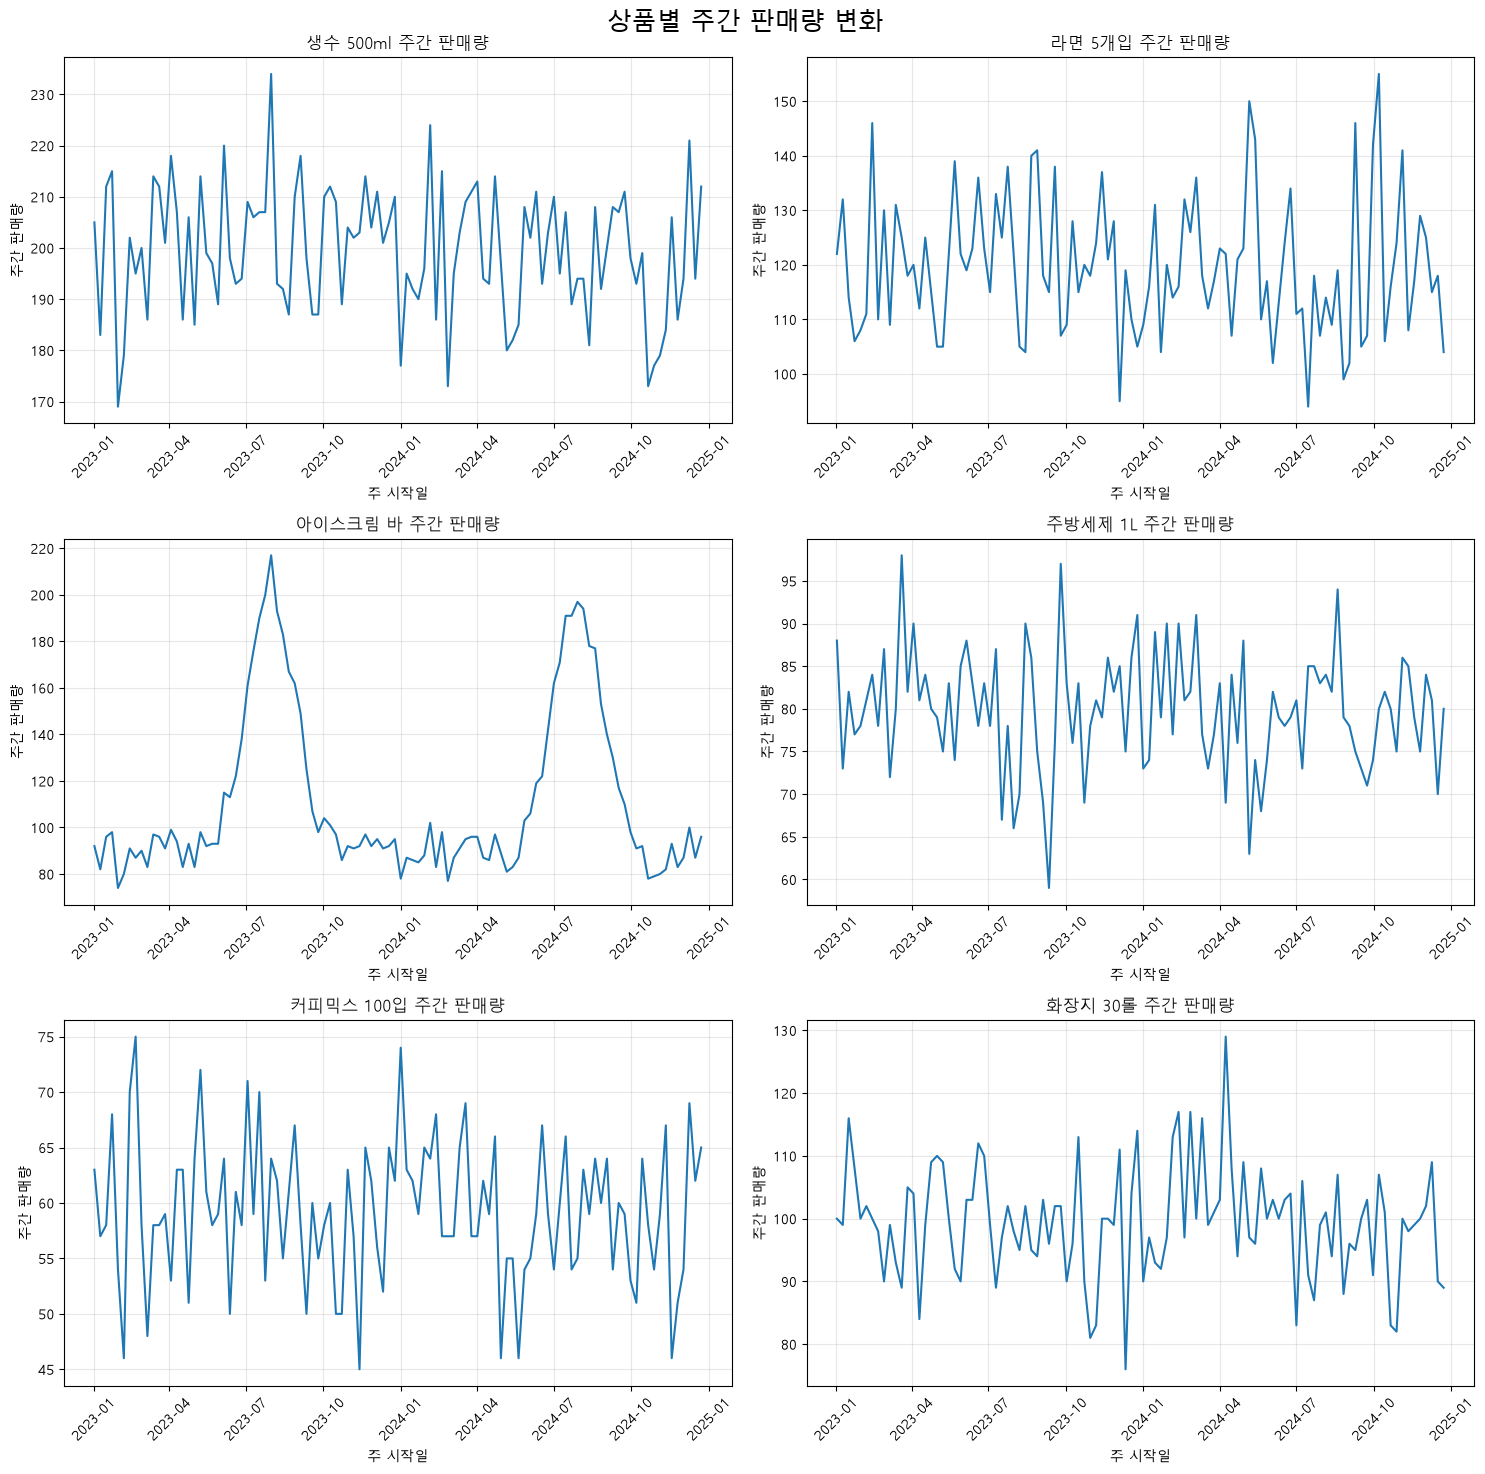

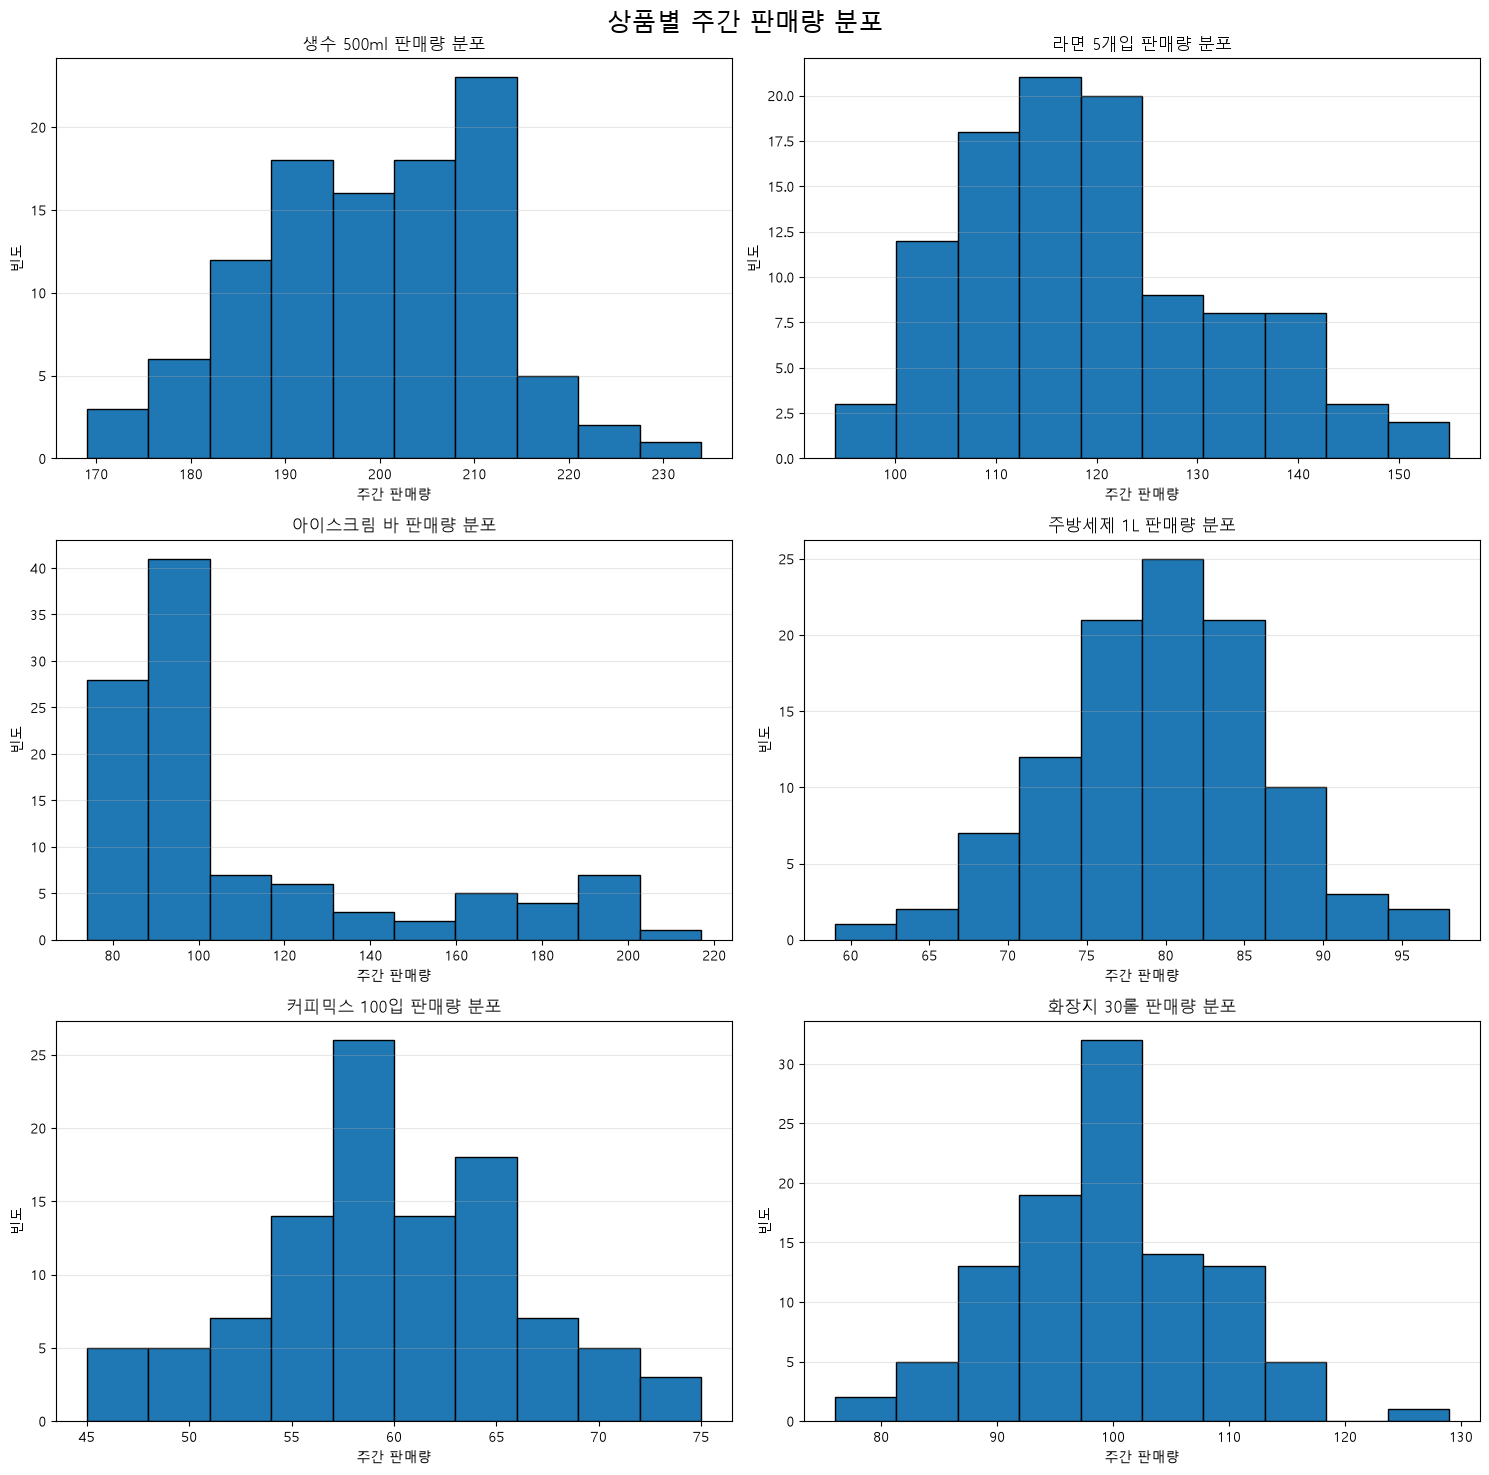

④ 상품별 평균 판매량


,상품 ID,상품명,평균 주간 판매량
0,SKU-01,생수 500ml,199.43
1,SKU-02,라면 5개입,119.62
2,SKU-03,아이스크림 바,110.90
3,SKU-04,주방세제 1L,79.80
4,SKU-05,커피믹스 100입,59.24
5,SKU-06,화장지 30롤,99.41


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# 한글 폰트 설정 (Windows)
# =========================
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


# =========================
# ① 파일 불러오기 + 열 확인
# =========================
df = pd.read_csv('demand_train.csv')

print("① 데이터 열")
print(df.columns.tolist())

print("\n데이터 미리보기")
display(df.head())

print("\n상품 목록")
print(df['sku_name'].unique())

# 날짜 형식으로 변환
df['week_start_date'] = pd.to_datetime(df['week_start_date'])

products = df['sku_name'].unique()


# =========================
# ② 상품별 주간 판매량 선그래프
#    3행 × 2열
# =========================
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, product in enumerate(products):

    product_data = (
        df[df['sku_name'] == product]
        .sort_values('week_start_date')
    )

    axes[i].plot(
        product_data['week_start_date'],
        product_data['weekly_demand_units']
    )

    axes[i].set_title(f'{product} 주간 판매량')
    axes[i].set_xlabel('주 시작일')
    axes[i].set_ylabel('주간 판매량')
    axes[i].grid(alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle('상품별 주간 판매량 변화', fontsize=18)
plt.tight_layout()
plt.show()


# =========================
# ③ 상품별 판매량 분포 막대그래프
#    3행 × 2열
# =========================
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, product in enumerate(products):

    product_data = df[
        df['sku_name'] == product
    ]['weekly_demand_units']

    axes[i].hist(
        product_data,
        bins=10,
        edgecolor='black'
    )

    axes[i].set_title(f'{product} 판매량 분포')
    axes[i].set_xlabel('주간 판매량')
    axes[i].set_ylabel('빈도')
    axes[i].grid(axis='y', alpha=0.3)

plt.suptitle('상품별 주간 판매량 분포', fontsize=18)
plt.tight_layout()
plt.show()


# =========================
# ④ 상품별 평균 판매량 표
# =========================
average_sales = (
    df.groupby(['sku_id', 'sku_name'])['weekly_demand_units']
      .mean()
      .reset_index()
)

average_sales.columns = [
    '상품 ID',
    '상품명',
    '평균 주간 판매량'
]

average_sales['평균 주간 판매량'] = (
    average_sales['평균 주간 판매량'].round(2)
)

print("④ 상품별 평균 판매량")
display(average_sales)

In [6]:
# ============================================================
# 0. 라이브러리
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import math
import numpy as np
import pandas as pd

from scipy.stats import norm

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error

from sklearn.linear_model import LinearRegression, Ridge

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from sklearn.neighbors import KNeighborsRegressor

from openpyxl import load_workbook
from openpyxl.styles import Alignment, Font


# ============================================================
# 1. 파일 설정
# ============================================================

DEMAND_FILE = "demand_train(1).csv"
MASTER_FILE = "sku_master(1).csv"

VALID_WEEKS = 13
FUTURE_WEEKS = 13

SERVICE_LEVELS = [
    0.90,
    0.95,
    0.98,
    0.99
]

REVIEW_PERIOD = 1

GRID_COVERAGE_WEEKS = [
    0.5,
    1.0,
    1.5,
    2.0,
    2.5,
    3.0
]


# ============================================================
# 2. 데이터 불러오기
# ============================================================

demand = pd.read_csv(DEMAND_FILE)
master = pd.read_csv(MASTER_FILE)

demand["week_start_date"] = pd.to_datetime(
    demand["week_start_date"]
)

demand = demand.sort_values(
    ["sku_id", "week_start_date"]
).reset_index(drop=True)


print("수요 데이터 :", demand.shape)
print("SKU 정보 :", master.shape)


# ============================================================
# 3. Feature 생성
# ============================================================

FEATURE_COLS = [
    "lag1",
    "lag2",
    "lag4",
    "rolling4",
    "rolling8",
    "month",
    "week_sin",
    "week_cos",
    "trend"
]


def make_features(df):

    df = df.copy()

    df = df.sort_values(
        "week_start_date"
    ).reset_index(drop=True)

    # 과거 수요
    df["lag1"] = df["weekly_demand_units"].shift(1)
    df["lag2"] = df["weekly_demand_units"].shift(2)
    df["lag4"] = df["weekly_demand_units"].shift(4)

    # 이동평균
    df["rolling4"] = (
        df["weekly_demand_units"]
        .shift(1)
        .rolling(4)
        .mean()
    )

    df["rolling8"] = (
        df["weekly_demand_units"]
        .shift(1)
        .rolling(8)
        .mean()
    )

    # 월
    df["month"] = df["week_start_date"].dt.month

    # 주차
    week_num = (
        df["week_start_date"]
        .dt.isocalendar()
        .week
        .astype(int)
    )

    # 계절성
    df["week_sin"] = np.sin(
        2 * np.pi * week_num / 52
    )

    df["week_cos"] = np.cos(
        2 * np.pi * week_num / 52
    )

    # 추세
    df["trend"] = np.arange(len(df))

    return df


# ============================================================
# 4. 다음 주 Feature
# ============================================================

def make_next_feature(history, next_date):

    week_num = int(
        next_date.isocalendar().week
    )

    return pd.DataFrame({

        "lag1": [
            history["weekly_demand_units"].iloc[-1]
        ],

        "lag2": [
            history["weekly_demand_units"].iloc[-2]
        ],

        "lag4": [
            history["weekly_demand_units"].iloc[-4]
        ],

        "rolling4": [
            history["weekly_demand_units"]
            .iloc[-4:]
            .mean()
        ],

        "rolling8": [
            history["weekly_demand_units"]
            .iloc[-8:]
            .mean()
        ],

        "month": [
            next_date.month
        ],

        "week_sin": [
            np.sin(
                2 * np.pi * week_num / 52
            )
        ],

        "week_cos": [
            np.cos(
                2 * np.pi * week_num / 52
            )
        ],

        "trend": [
            len(history)
        ]
    })


# ============================================================
# 5. 재귀 예측
# ============================================================

def recursive_forecast(
    model,
    history,
    periods=13,
    future_dates=None
):

    history = history.copy()

    predictions = []
    dates = []

    last_date = (
        history["week_start_date"]
        .iloc[-1]
    )

    for i in range(periods):

        if future_dates is None:

            next_date = (
                last_date
                + pd.Timedelta(
                    weeks=i + 1
                )
            )

        else:

            next_date = pd.to_datetime(
                future_dates[i]
            )

        X_next = make_next_feature(
            history,
            next_date
        )

        pred = float(
            model.predict(
                X_next
            )[0]
        )

        pred = max(
            pred,
            0
        )

        predictions.append(
            pred
        )

        dates.append(
            next_date
        )

        # 다음 주 예측에 이번 예측값 사용
        new_row = pd.DataFrame({

            "week_start_date": [
                next_date
            ],

            "weekly_demand_units": [
                pred
            ]
        })

        history = pd.concat(
            [
                history,
                new_row
            ],
            ignore_index=True
        )

    return (
        np.array(predictions),
        dates
    )


# ============================================================
# 6. MAPE
# ============================================================

def calc_mape(actual, pred):

    actual = np.asarray(
        actual,
        dtype=float
    )

    pred = np.asarray(
        pred,
        dtype=float
    )

    mask = actual != 0

    return (
        np.mean(
            np.abs(
                (
                    actual[mask]
                    - pred[mask]
                )
                / actual[mask]
            )
        )
        * 100
    )


# ============================================================
# 7. 후보 모델
# ============================================================

def get_candidate_models():

    return {

        "LinearRegression":
            LinearRegression(),

        "Ridge":
            Ridge(
                alpha=1.0
            ),

        "RandomForest":
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            ),

        "ExtraTrees":
            ExtraTreesRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            ),

        "GradientBoosting":
            GradientBoostingRegressor(
                random_state=42
            ),

        "KNN":
            KNeighborsRegressor(
                n_neighbors=5
            )
    }


# ============================================================
# 8. 모델 비교
# 91주 학습 → 13주 검증
# ============================================================

def select_best_model(
    train_raw,
    valid_raw
):

    train_feature = (
        make_features(
            train_raw
        )
        .dropna()
        .copy()
    )

    X_train = (
        train_feature[
            FEATURE_COLS
        ]
    )

    y_train = (
        train_feature[
            "weekly_demand_units"
        ]
    )

    actual = (
        valid_raw[
            "weekly_demand_units"
        ]
        .to_numpy(
            dtype=float
        )
    )

    valid_dates = (
        valid_raw[
            "week_start_date"
        ]
        .tolist()
    )

    model_results = []

    best_model = None
    best_name = None
    best_pred = None
    best_mape = np.inf

    for name, model in get_candidate_models().items():

        try:

            fitted = clone(
                model
            )

            fitted.fit(
                X_train,
                y_train
            )

            pred, _ = recursive_forecast(

                model=fitted,

                history=train_raw[
                    [
                        "week_start_date",
                        "weekly_demand_units"
                    ]
                ],

                periods=VALID_WEEKS,

                future_dates=valid_dates
            )

            mae = mean_absolute_error(
                actual,
                pred
            )

            rmse = np.sqrt(
                mean_squared_error(
                    actual,
                    pred
                )
            )

            mape = calc_mape(
                actual,
                pred
            )

            model_results.append({

                "모델":
                    name,

                "MAE":
                    mae,

                "RMSE":
                    rmse,

                "MAPE(%)":
                    mape
            })

            if mape < best_mape:

                best_mape = mape
                best_model = fitted
                best_name = name
                best_pred = pred

        except Exception as e:

            print(
                name,
                "실패 :",
                e
            )

    result_df = pd.DataFrame(
        model_results
    ).sort_values(
        "MAPE(%)"
    ).reset_index(
        drop=True
    )

    return (
        best_name,
        best_model,
        best_pred,
        result_df
    )


# ============================================================
# 9. 주문량 보정
# ============================================================

def adjust_order_quantity(
    quantity,
    moq,
    order_multiple
):

    if quantity <= 0:
        return 0

    quantity = max(
        quantity,
        moq
    )

    quantity = (
        math.ceil(
            quantity
            / order_multiple
        )
        * order_multiple
    )

    return int(
        quantity
    )


# ============================================================
# 10. EOQ
# ============================================================

def calculate_eoq(
    weekly_demand,
    fixed_order_cost,
    weekly_holding_cost
):

    annual_demand = (
        weekly_demand
        * 52
    )

    annual_holding_cost = (
        weekly_holding_cost
        * 52
    )

    if annual_holding_cost <= 0:
        return 0

    return np.sqrt(
        (
            2
            * annual_demand
            * fixed_order_cost
        )
        /
        annual_holding_cost
    )


# ============================================================
# 11. s, S 계산
# ============================================================

def calculate_sS(
    method,
    expected_weekly_demand,
    sigma,
    service_level,
    lead_time,
    moq,
    order_multiple,
    eoq_q=None,
    coverage_weeks=None
):

    d = max(
        float(
            expected_weekly_demand
        ),
        0
    )

    z = norm.ppf(
        service_level
    )

    # 안전재고
    safety_stock = (
        z
        * sigma
        * np.sqrt(
            lead_time
        )
    )

    # 재주문점
    s = (
        d
        * lead_time
        + safety_stock
    )


    # ------------------------------------
    # 1. EOQ
    # ------------------------------------

    if method == "EOQ":

        gap = adjust_order_quantity(
            eoq_q,
            moq,
            order_multiple
        )

        S = (
            s
            + gap
        )


    # ------------------------------------
    # 2. Order-up-to
    # ------------------------------------

    elif method == "ORDER_UP_TO":

        protection_period = (
            lead_time
            + REVIEW_PERIOD
        )

        protection_safety = (
            z
            * sigma
            * np.sqrt(
                protection_period
            )
        )

        raw_S = (
            d
            * protection_period
            + protection_safety
        )

        raw_gap = max(
            raw_S - s,
            moq
        )

        gap = adjust_order_quantity(
            raw_gap,
            moq,
            order_multiple
        )

        S = (
            s
            + gap
        )


    # ------------------------------------
    # 3. Grid
    # ------------------------------------

    elif method == "GRID":

        raw_gap = (
            d
            * coverage_weeks
        )

        gap = adjust_order_quantity(
            raw_gap,
            moq,
            order_multiple
        )

        S = (
            s
            + gap
        )

    else:

        raise ValueError(
            "정책 오류"
        )

    return {

        "s":
            float(s),

        "S":
            float(S),

        "z":
            float(z),

        "safety_stock":
            float(safety_stock)
    }


# ============================================================
# 12. 재고정책 시뮬레이션
# ============================================================

def simulate_policy(
    actual_demand,
    forecast_reference,
    method,
    sigma,
    service_level,
    sku_info,
    eoq_q=None,
    coverage_weeks=None
):

    actual_demand = np.asarray(
        actual_demand,
        dtype=float
    )

    lead_time = int(
        sku_info[
            "lead_time_weeks"
        ]
    )

    moq = int(
        sku_info[
            "minimum_order_quantity_units"
        ]
    )

    order_multiple = int(
        sku_info[
            "order_multiple_units"
        ]
    )

    fixed_order_cost = float(
        sku_info[
            "fixed_order_cost_krw_per_order"
        ]
    )

    holding_cost = float(
        sku_info[
            "weekly_holding_cost_krw_per_unit"
        ]
    )

    shortage_cost = float(
        sku_info[
            "shortage_penalty_cost_krw_per_unit"
        ]
    )

    levels = calculate_sS(

        method=
            method,

        expected_weekly_demand=
            forecast_reference,

        sigma=
            sigma,

        service_level=
            service_level,

        lead_time=
            lead_time,

        moq=
            moq,

        order_multiple=
            order_multiple,

        eoq_q=
            eoq_q,

        coverage_weeks=
            coverage_weeks
    )

    s = levels["s"]
    S = levels["S"]


    # 모든 정책 동일 시작재고
    on_hand = math.ceil(
        forecast_reference
        * (
            lead_time
            + 1
        )
    )

    scheduled_arrivals = {}

    total_order_cost = 0
    total_holding_cost = 0
    total_shortage_cost = 0

    total_shortage_units = 0

    for t, demand_t in enumerate(
        actual_demand
    ):

        # 입고
        arrival = (
            scheduled_arrivals
            .pop(
                t,
                0
            )
        )

        on_hand += arrival

        on_order = sum(
            scheduled_arrivals.values()
        )

        inventory_position = (
            on_hand
            + on_order
        )

        # 주문
        if inventory_position <= s:

            raw_order = (
                S
                - inventory_position
            )

            order_qty = adjust_order_quantity(
                raw_order,
                moq,
                order_multiple
            )

            if order_qty > 0:

                arrival_week = (
                    t
                    + lead_time
                )

                scheduled_arrivals[
                    arrival_week
                ] = (
                    scheduled_arrivals.get(
                        arrival_week,
                        0
                    )
                    + order_qty
                )

                total_order_cost += (
                    fixed_order_cost
                )

        # 수요 발생
        shortage = max(
            demand_t
            - on_hand,
            0
        )

        on_hand = max(
            on_hand
            - demand_t,
            0
        )

        total_holding_cost += (
            on_hand
            * holding_cost
        )

        total_shortage_cost += (
            shortage
            * shortage_cost
        )

        total_shortage_units += (
            shortage
        )

    total_cost = (
        total_order_cost
        + total_holding_cost
        + total_shortage_cost
    )

    total_demand = (
        actual_demand.sum()
    )

    if total_demand > 0:

        fill_rate = (
            1
            - (
                total_shortage_units
                / total_demand
            )
        )

    else:

        fill_rate = 1

    return {

        "s":
            s,

        "S":
            S,

        "총비용":
            total_cost,

        "Fill_Rate":
            fill_rate
    }


# ============================================================
# 13. 상품별 분석
# ============================================================

def analyze_sku(
    sku_id
):

    print("\n" + "=" * 80)

    sku_df = (
        demand[
            demand["sku_id"]
            == sku_id
        ]
        .sort_values(
            "week_start_date"
        )
        .reset_index(drop=True)
    )

    sku_info = (
        master[
            master["sku_id"]
            == sku_id
        ]
        .iloc[0]
    )

    sku_name = (
        sku_info[
            "sku_name"
        ]
    )

    print(
        sku_id,
        sku_name
    )


    # ========================================================
    # 91주 학습 / 13주 검증
    # ========================================================

    train_raw = (
        sku_df.iloc[
            :-VALID_WEEKS
        ]
        .copy()
    )

    valid_raw = (
        sku_df.iloc[
            -VALID_WEEKS:
        ]
        .copy()
    )


    # ========================================================
    # 모델 비교
    # ========================================================

    (
        best_model_name,
        best_model,
        valid_pred,
        model_compare_df

    ) = select_best_model(
        train_raw,
        valid_raw
    )


    actual = (
        valid_raw[
            "weekly_demand_units"
        ]
        .to_numpy(
            dtype=float
        )
    )

    errors = (
        actual
        - valid_pred
    )

    mape = calc_mape(
        actual,
        valid_pred
    )

    sigma = np.std(
        errors,
        ddof=0
    )


    print(
        "최적 모델 :",
        best_model_name
    )

    print(
        "13주 MAPE :",
        round(
            mape,
            2
        ),
        "%"
    )

    print(
        "오차 표준편차 :",
        round(
            sigma,
            2
        )
    )


    # ========================================================
    # EOQ 정보
    # ========================================================

    fixed_order_cost = float(
        sku_info[
            "fixed_order_cost_krw_per_order"
        ]
    )

    holding_cost = float(
        sku_info[
            "weekly_holding_cost_krw_per_unit"
        ]
    )

    moq = int(
        sku_info[
            "minimum_order_quantity_units"
        ]
    )

    order_multiple = int(
        sku_info[
            "order_multiple_units"
        ]
    )


    validation_eoq = calculate_eoq(

        train_raw[
            "weekly_demand_units"
        ].mean(),

        fixed_order_cost,

        holding_cost
    )


    validation_eoq = adjust_order_quantity(
        validation_eoq,
        moq,
        order_multiple
    )


    # ========================================================
    # 정책 비교
    # ========================================================

    forecast_reference = (
        valid_pred.mean()
    )

    policy_candidates = []


    # EOQ
    for sl in SERVICE_LEVELS:

        sim = simulate_policy(

            actual_demand=
                actual,

            forecast_reference=
                forecast_reference,

            method=
                "EOQ",

            sigma=
                sigma,

            service_level=
                sl,

            sku_info=
                sku_info,

            eoq_q=
                validation_eoq
        )

        policy_candidates.append({

            "policy":
                "EOQ",

            "service":
                sl,

            "coverage":
                None,

            **sim
        })


    # Order-up-to
    for sl in SERVICE_LEVELS:

        sim = simulate_policy(

            actual_demand=
                actual,

            forecast_reference=
                forecast_reference,

            method=
                "ORDER_UP_TO",

            sigma=
                sigma,

            service_level=
                sl,

            sku_info=
                sku_info
        )

        policy_candidates.append({

            "policy":
                "ORDER_UP_TO",

            "service":
                sl,

            "coverage":
                None,

            **sim
        })


    # Grid Search
    for sl in SERVICE_LEVELS:

        for coverage in GRID_COVERAGE_WEEKS:

            sim = simulate_policy(

                actual_demand=
                    actual,

                forecast_reference=
                    forecast_reference,

                method=
                    "GRID",

                sigma=
                    sigma,

                service_level=
                    sl,

                sku_info=
                    sku_info,

                coverage_weeks=
                    coverage
            )

            policy_candidates.append({

                "policy":
                    "GRID",

                "service":
                    sl,

                "coverage":
                    coverage,

                **sim
            })


    # 최저 비용 정책
    best_policy = min(

        policy_candidates,

        key=lambda x:
            x["총비용"]
    )


    print(
        "최적 재고정책 :",
        best_policy[
            "policy"
        ]
    )

    print(
        "서비스 수준 :",
        int(
            best_policy[
                "service"
            ]
            * 100
        ),
        "%"
    )


    # ========================================================
    # 104주 전체 재학습
    # ========================================================

    full_feature = (
        make_features(
            sku_df
        )
        .dropna()
        .copy()
    )


    final_model = clone(
        get_candidate_models()[
            best_model_name
        ]
    )


    final_model.fit(

        full_feature[
            FEATURE_COLS
        ],

        full_feature[
            "weekly_demand_units"
        ]
    )


    # ========================================================
    # 미래 13주 예측
    # ========================================================

    future_pred, future_dates = recursive_forecast(

        model=
            final_model,

        history=
            sku_df[
                [
                    "week_start_date",
                    "weekly_demand_units"
                ]
            ],

        periods=
            FUTURE_WEEKS
    )


    future_avg = (
        future_pred.mean()
    )


    # ========================================================
    # 최종 EOQ
    # ========================================================

    final_eoq = calculate_eoq(

        sku_df[
            "weekly_demand_units"
        ].mean(),

        fixed_order_cost,

        holding_cost
    )


    final_eoq = adjust_order_quantity(
        final_eoq,
        moq,
        order_multiple
    )


    # ========================================================
    # 최종 s, S
    # ========================================================

    if (
        best_policy[
            "policy"
        ]
        == "EOQ"
    ):

        method_code = "EOQ"

    elif (
        best_policy[
            "policy"
        ]
        == "ORDER_UP_TO"
    ):

        method_code = "ORDER_UP_TO"

    else:

        method_code = "GRID"


    final_levels = calculate_sS(

        method=
            method_code,

        expected_weekly_demand=
            future_avg,

        sigma=
            sigma,

        service_level=
            best_policy[
                "service"
            ],

        lead_time=
            int(
                sku_info[
                    "lead_time_weeks"
                ]
            ),

        moq=
            moq,

        order_multiple=
            order_multiple,

        eoq_q=
            final_eoq,

        coverage_weeks=
            best_policy[
                "coverage"
            ]
    )


    final_s = math.ceil(
        final_levels[
            "s"
        ]
    )

    final_S = math.ceil(
        final_levels[
            "S"
        ]
    )


    print(
        "최종 s :",
        final_s
    )

    print(
        "최종 S :",
        final_S
    )


    return {

        "sku_id":
            sku_id,

        "상품명":
            sku_name,

        "모델":
            best_model_name,

        "MAPE":
            mape,

        "sigma":
            sigma,

        "정책":
            best_policy[
                "policy"
            ],

        "서비스수준":
            best_policy[
                "service"
            ],

        "s":
            final_s,

        "S":
            final_S
    }


# ============================================================
# 14. 6개 SKU 실행
# ============================================================

results = []


for sku_id in master[
    "sku_id"
]:

    result = analyze_sku(
        sku_id
    )

    results.append(
        result
    )


# ============================================================
# 15. 전체 결과
# ============================================================

result_df = pd.DataFrame(
    results
)


print("\n")
print("=" * 80)
print("전체 결과")
print("=" * 80)

display(
    result_df
)


# ============================================================
# 16. 최종 제출용 표
# 사진 형식 : 1~6 / s / S
# ============================================================

result_simple = (

    result_df

    .sort_values(
        "sku_id"
    )

    .reset_index(
        drop=True
    )

    [
        [
            "s",
            "S"
        ]
    ]

    .copy()
)


result_simple.insert(

    0,

    "",

    range(
        1,
        len(result_simple) + 1
    )
)


print("\n")
print("=" * 80)
print("최종 제출용")
print("=" * 80)

display(
    result_simple
)


# ============================================================
# 17. Excel 저장
# ============================================================

OUTPUT_FILE = (
    "최종_sS_제출용.xlsx"
)


with pd.ExcelWriter(
    OUTPUT_FILE,
    engine="openpyxl"
) as writer:

    result_simple.to_excel(
        writer,
        sheet_name="사용할데이터",
        index=False
    )


# ============================================================
# 18. Excel 간단 서식
# ============================================================

wb = load_workbook(
    OUTPUT_FILE
)

ws = wb[
    "사용할데이터"
]


for row in ws.iter_rows():

    for cell in row:

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center"
        )


for cell in ws[1]:

    cell.font = Font(
        bold=True
    )


ws.column_dimensions[
    "A"
].width = 8

ws.column_dimensions[
    "B"
].width = 12

ws.column_dimensions[
    "C"
].width = 12


wb.save(
    OUTPUT_FILE
)


print(
    "\n저장 완료 :",
    OUTPUT_FILE
)

FileNotFoundError: [Errno 2] No such file or directory: 'demand_train(1).csv'

전체 데이터: 104 주
학습 데이터: 78 주
테스트 데이터: 26 주


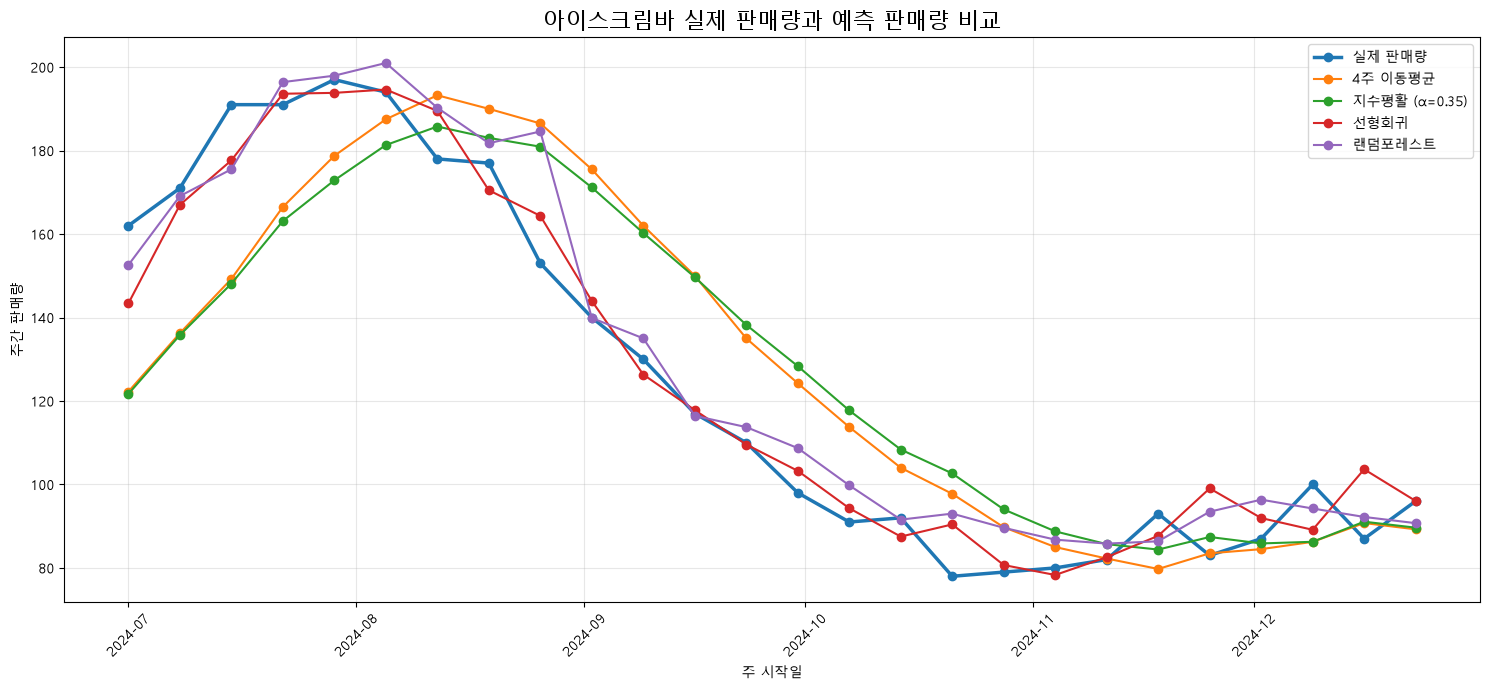

예측 결과


,주 시작일,실제 판매량,4주 이동평균,지수평활,선형회귀,랜덤포레스트
0,2024-07-01,162,122.2,121.7,143.4,152.6
1,2024-07-08,171,136.2,135.8,167.0,169.1
2,2024-07-15,191,149.2,148.1,177.7,175.5
3,2024-07-22,191,166.5,163.1,193.6,196.4
4,2024-07-29,197,178.8,172.9,193.8,197.9
5,2024-08-05,194,187.5,181.3,194.6,201.0
6,2024-08-12,178,193.2,185.8,189.5,190.2
7,2024-08-19,177,190.0,183.0,170.5,181.8
8,2024-08-26,153,186.5,180.9,164.4,184.6
9,2024-09-02,140,175.5,171.2,144.0,139.9


모델별 MAE


,예측 방법,MAE
2,선형회귀,6.30
3,랜덤포레스트,7.58
0,4주 이동평균,18.85
1,지수평활,19.65



각 예측 방법 설명
① 4주 이동평균 : 최근 4주의 실제 판매량 평균으로 다음 주 판매량을 예측합니다.
② 지수평활     : 최근 판매량에 더 큰 비중을 주며, alpha=0.35로 다음 주 판매량을 예측합니다.
③ 선형회귀     : 1주 전 수요, 2주 전 수요, 최근 4주 평균, 월 정보를 이용해 다음 주 판매량을 예측합니다.
④ 랜덤포레스트 : 과거 판매 패턴과 월 정보를 여러 결정트리가 학습하여 다음 주 판매량을 예측합니다.


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error


 # 한글 폰트 설정
 plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


 # 데이터 불러오기
 df = pd.read_csv('demand_train.csv')

# 아이스크림바 데이터만 선택
ice = df[df['sku_name'] == '아이스크림 바'].copy()

# 날짜 변환 및 정렬
ice['week_start_date'] = pd.to_datetime(ice['week_start_date'])

ice = (
    ice.sort_values('week_start_date')
       .reset_index(drop=True)
)

# 월 정보 생성
ice['month'] = ice['week_start_date'].dt.month

print("전체 데이터:", len(ice), "주")


 # ① 학습 78주 / 테스트 26주
 train_size = len(ice) - 26

train = ice.iloc[:train_size].copy()
test = ice.iloc[train_size:].copy()

train_sales = train['weekly_demand_units'].values
test_sales = test['weekly_demand_units'].values

print("학습 데이터:", len(train), "주")
print("테스트 데이터:", len(test), "주")


 # ②-1. 4주 이동평균
 history = list(train_sales)

ma_predictions = []

for actual in test_sales:

    pred = np.mean(history[-4:])

    ma_predictions.append(pred)

    # 예측한 후 실제 판매량 추가
    history.append(actual)


 # ②-2. 지수평활
# alpha = 0.35
 
alpha = 0.35

history = list(train_sales)

exp_predictions = []

for actual in test_sales:

    # 첫 번째 값으로 초기화
    level = history[0]

    # 지수평활 계산
    for value in history[1:]:

        level = (
            alpha * value
            + (1 - alpha) * level
        )

    # 현재 level이 다음 주 예측값
    exp_predictions.append(level)

    # 실제값 추가
    history.append(actual)


 # 선형회귀용 데이터 생성 함수
#
# 입력 변수:
# 1주 전 수요
# 2주 전 수요
# 최근 4주 평균
# 월
 def make_regression_data(data):

    X = []
    y = []

    for i in range(4, len(data)):

        lag1 = data.loc[i - 1, 'weekly_demand_units']
        lag2 = data.loc[i - 2, 'weekly_demand_units']

        avg4 = data.loc[
            i - 4:i - 1,
            'weekly_demand_units'
        ].mean()

        month = data.loc[i, 'month']

        X.append([
            lag1,
            lag2,
            avg4,
            month
        ])

        y.append(
            data.loc[i, 'weekly_demand_units']
        )

    return np.array(X), np.array(y)


 # ②-3. 선형회귀
 history_df = train[
    [
        'week_start_date',
        'weekly_demand_units',
        'month'
    ]
].copy()

history_df = history_df.reset_index(drop=True)

lr_predictions = []


for i in range(len(test)):

    # 현재까지 확보된 데이터로 학습용 데이터 생성
    X_train, y_train = make_regression_data(
        history_df
    )

    # 모델 학습
    lr_model = LinearRegression()

    lr_model.fit(
        X_train,
        y_train
    )

     # 다음 주 입력값 만들기
 
    lag1 = history_df[
        'weekly_demand_units'
    ].iloc[-1]

    lag2 = history_df[
        'weekly_demand_units'
    ].iloc[-2]

    avg4 = history_df[
        'weekly_demand_units'
    ].iloc[-4:].mean()

    # 예측하려는 주의 월
    next_month = test.iloc[i]['month']

    X_next = np.array([
        [
            lag1,
            lag2,
            avg4,
            next_month
        ]
    ])

    pred = lr_model.predict(X_next)[0]

    lr_predictions.append(pred)

     # 예측 후 실제값 추가
     new_row = pd.DataFrame({

        'week_start_date': [
            test.iloc[i]['week_start_date']
        ],

        'weekly_demand_units': [
            test.iloc[i]['weekly_demand_units']
        ],

        'month': [
            test.iloc[i]['month']
        ]
    })

    history_df = pd.concat(
        [history_df, new_row],
        ignore_index=True
    )


 # ②-4. 랜덤포레스트
#
# 선형회귀와 동일하게
# lag1, lag2, 4주 평균, 월 사용
 history_df = train[
    [
        'week_start_date',
        'weekly_demand_units',
        'month'
    ]
].copy()

history_df = history_df.reset_index(drop=True)

rf_predictions = []


for i in range(len(test)):

    X_train, y_train = make_regression_data(
        history_df
    )

    rf_model = RandomForestRegressor(
        n_estimators=300,
        random_state=42
    )

    rf_model.fit(
        X_train,
        y_train
    )

    lag1 = history_df[
        'weekly_demand_units'
    ].iloc[-1]

    lag2 = history_df[
        'weekly_demand_units'
    ].iloc[-2]

    avg4 = history_df[
        'weekly_demand_units'
    ].iloc[-4:].mean()

    next_month = test.iloc[i]['month']

    X_next = np.array([
        [
            lag1,
            lag2,
            avg4,
            next_month
        ]
    ])

    pred = rf_model.predict(X_next)[0]

    rf_predictions.append(pred)

    # 예측 후 실제값 추가
    new_row = pd.DataFrame({

        'week_start_date': [
            test.iloc[i]['week_start_date']
        ],

        'weekly_demand_units': [
            test.iloc[i]['weekly_demand_units']
        ],

        'month': [
            test.iloc[i]['month']
        ]
    })

    history_df = pd.concat(
        [history_df, new_row],
        ignore_index=True
    )


 # ③ 실제 판매량 + 예측값 그래프
 plt.figure(figsize=(15, 7))


# 실제값
plt.plot(
    test['week_start_date'],
    test_sales,
    marker='o',
    linewidth=2.5,
    label='실제 판매량'
)


# 이동평균
plt.plot(
    test['week_start_date'],
    ma_predictions,
    marker='o',
    label='4주 이동평균'
)


# 지수평활
plt.plot(
    test['week_start_date'],
    exp_predictions,
    marker='o',
    label='지수평활 (α=0.35)'
)


# 선형회귀
plt.plot(
    test['week_start_date'],
    lr_predictions,
    marker='o',
    label='선형회귀'
)


# 랜덤포레스트
plt.plot(
    test['week_start_date'],
    rf_predictions,
    marker='o',
    label='랜덤포레스트'
)


plt.title(
    '아이스크림바 실제 판매량과 예측 판매량 비교',
    fontsize=16
)

plt.xlabel('주 시작일')
plt.ylabel('주간 판매량')

plt.legend()

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


 # 예측 결과 표
 result = pd.DataFrame({

    '주 시작일':
        test['week_start_date'].values,

    '실제 판매량':
        test_sales,

    '4주 이동평균':
        np.round(ma_predictions, 1),

    '지수평활':
        np.round(exp_predictions, 1),

    '선형회귀':
        np.round(lr_predictions, 1),

    '랜덤포레스트':
        np.round(rf_predictions, 1)
})


print("예측 결과")

display(result)


 # MAE 비교
 mae_result = pd.DataFrame({

    '예측 방법': [
        '4주 이동평균',
        '지수평활',
        '선형회귀',
        '랜덤포레스트'
    ],

    'MAE': [

        mean_absolute_error(
            test_sales,
            ma_predictions
        ),

        mean_absolute_error(
            test_sales,
            exp_predictions
        ),

        mean_absolute_error(
            test_sales,
            lr_predictions
        ),

        mean_absolute_error(
            test_sales,
            rf_predictions
        )
    ]
})


mae_result['MAE'] = (
    mae_result['MAE']
    .round(2)
)


print("모델별 MAE")

display(
    mae_result.sort_values('MAE')
)



# 각 예측 방법 설명
print("\n각 예측 방법 설명")
print("① 4주 이동평균 : 최근 4주의 실제 판매량 평균으로 다음 주 판매량을 예측합니다.")
print("② 지수평활     : 최근 판매량에 더 큰 비중을 주며, alpha=0.35로 다음 주 판매량을 예측합니다.")
print("③ 선형회귀     : 1주 전 수요, 2주 전 수요, 최근 4주 평균, 월 정보를 이용해 다음 주 판매량을 예측합니다.")
print("④ 랜덤포레스트 : 과거 판매 패턴과 월 정보를 여러 결정트리가 학습하여 다음 주 판매량을 예측합니다.")

사용 데이터 열:
['주 시작일', '아이스크림바', '생수 500ml']

아이스크림바
학습 데이터: 40 주
테스트 데이터: 12 주


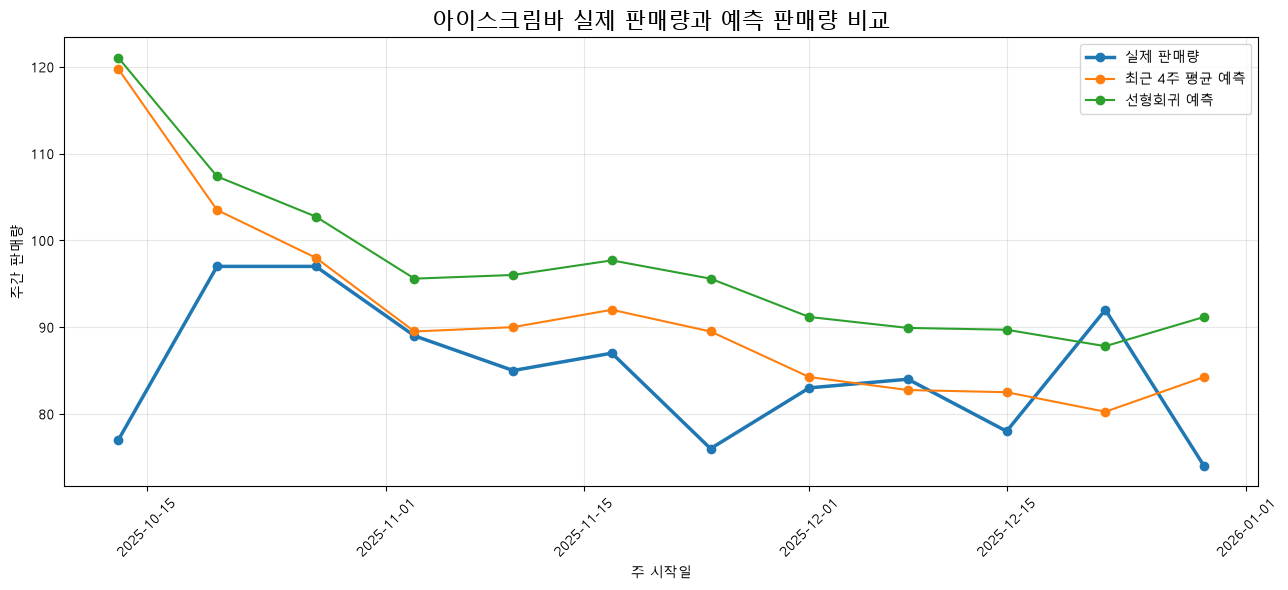


예측 결과


,주 시작일,실제 판매량,최근 4주 평균 예측,선형회귀 예측
0,2025-10-13,77,119.8,121.0
1,2025-10-20,97,103.5,107.4
2,2025-10-27,97,98.0,102.7
3,2025-11-03,89,89.5,95.6
4,2025-11-10,85,90.0,96.0
5,2025-11-17,87,92.0,97.7
6,2025-11-24,76,89.5,95.6
7,2025-12-01,83,84.2,91.2
8,2025-12-08,84,82.8,89.9
9,2025-12-15,78,82.5,89.7



예측 오차 비교


,방법,MAE
0,최근 4주 평균,8.60
1,선형회귀,12.93



방법 설명
① 최근 4주 평균 : 직전 4주의 실제 판매량 평균을 다음 주 판매량으로 예측했습니다.
② 선형회귀 : 과거 데이터에서 최근 4주 평균과 실제 판매량의 관계를 학습해 다음 주 판매량을 예측했습니다.

생수 500ml
학습 데이터: 40 주
테스트 데이터: 12 주


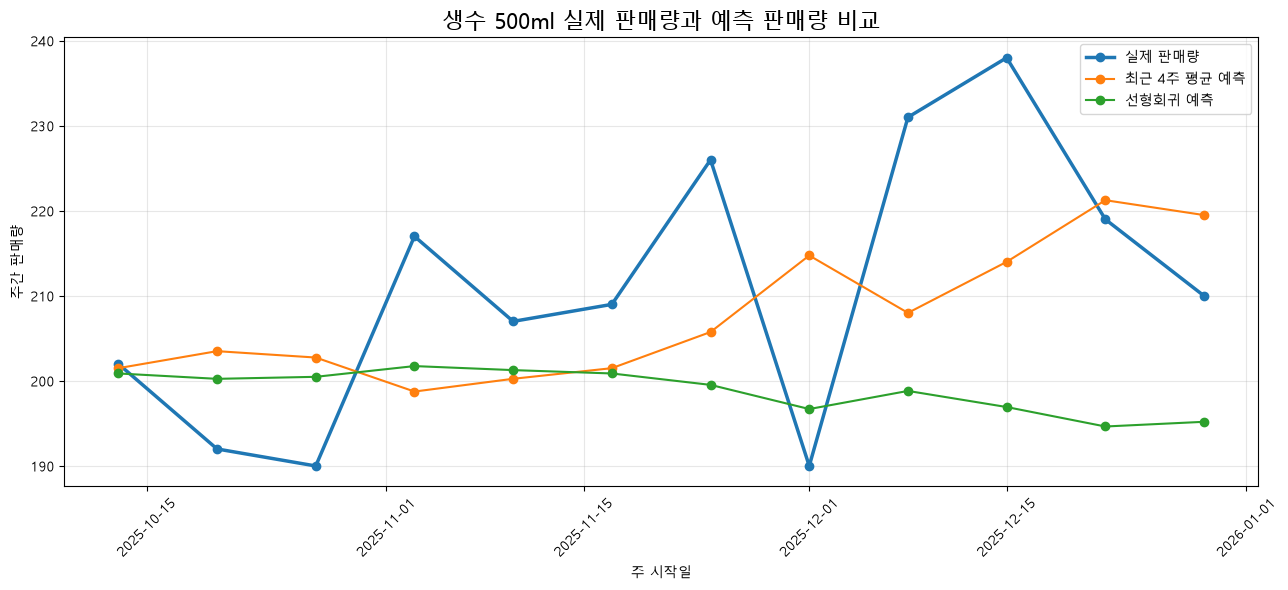


예측 결과


,주 시작일,실제 판매량,최근 4주 평균 예측,선형회귀 예측
0,2025-10-13,202,201.5,200.9
1,2025-10-20,192,203.5,200.2
2,2025-10-27,190,202.8,200.5
3,2025-11-03,217,198.8,201.7
4,2025-11-10,207,200.2,201.3
5,2025-11-17,209,201.5,200.9
6,2025-11-24,226,205.8,199.5
7,2025-12-01,190,214.8,196.7
8,2025-12-08,231,208.0,198.8
9,2025-12-15,238,214.0,196.9



예측 오차 비교


,방법,MAE
0,최근 4주 평균,13.42
1,선형회귀,16.21



방법 설명
① 최근 4주 평균 : 직전 4주의 실제 판매량 평균을 다음 주 판매량으로 예측했습니다.
② 선형회귀 : 과거 데이터에서 최근 4주 평균과 실제 판매량의 관계를 학습해 다음 주 판매량을 예측했습니다.


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error


# =========================
# 한글 폰트 설정
# =========================
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


# =========================
# 데이터 불러오기
# =========================
df = pd.read_excel(
    '[Step4]수강생예제실습.xlsx',
    sheet_name='주간수요'
)

# 필요한 열만 사용
df = df[
    [
        '주 시작일',
        '아이스크림바',
        '생수 500ml'
    ]
].copy()

df['주 시작일'] = pd.to_datetime(df['주 시작일'])

df = (
    df.sort_values('주 시작일')
      .reset_index(drop=True)
)

print("사용 데이터 열:")
print(df.columns.tolist())


# =========================
# 상품별 예측 함수
# =========================
def forecast_product(df, product):

    # =========================
    # ① 마지막 12주는 테스트
    # =========================
    train = df.iloc[:-12].copy()
    test = df.iloc[-12:].copy()

    print("\n" + "=" * 50)
    print(product)
    print("=" * 50)

    print("학습 데이터:", len(train), "주")
    print("테스트 데이터:", len(test), "주")


    # =========================
    # ②-1. 최근 4주 평균 예측
    # =========================
    history = list(train[product])

    moving_avg_pred = []

    for i in range(len(test)):

        # 직전 4주의 평균
        pred = np.mean(history[-4:])

        moving_avg_pred.append(pred)

        # 예측 후 실제값 확인
        actual = test.iloc[i][product]

        # 실제값을 다음 주 예측에 사용
        history.append(actual)


    # =========================
    # ②-2. 최근 4주 평균 기반 선형회귀
    # =========================

    model_data = train[[product]].copy()

    # 현재 주를 예측할 때 사용할
    # 직전 4주의 평균 생성
    model_data['최근4주평균'] = (
        model_data[product]
        .shift(1)
        .rolling(4)
        .mean()
    )

    # 처음 4개 행은 평균 계산이 불가능하므로 제거
    model_data = model_data.dropna().copy()


    # 입력값
    X_train = model_data[
        ['최근4주평균']
    ]

    # 정답
    y_train = model_data[product]


    # 선형회귀 학습
    model = LinearRegression()

    model.fit(
        X_train,
        y_train
    )


    # =========================
    # 테스트 12주를 한 주씩 예측
    # =========================
    history = list(train[product])

    linear_pred = []

    for i in range(len(test)):

        # 현재까지 실제 데이터의 최근 4주 평균
        avg4 = np.mean(
            history[-4:]
        )

        X_next = pd.DataFrame({
            '최근4주평균': [avg4]
        })

        # 다음 주 예측
        pred = model.predict(
            X_next
        )[0]

        linear_pred.append(pred)

        # 예측 후 실제값 확인
        actual = test.iloc[i][product]

        # 실제값을 다음 주 예측에 사용
        history.append(actual)


    # =========================
    # ③ 실제값 + 두 예측값 그래프
    # =========================
    plt.figure(
        figsize=(13, 6)
    )

    plt.plot(
        test['주 시작일'],
        test[product],
        marker='o',
        linewidth=2.5,
        label='실제 판매량'
    )

    plt.plot(
        test['주 시작일'],
        moving_avg_pred,
        marker='o',
        label='최근 4주 평균 예측'
    )

    plt.plot(
        test['주 시작일'],
        linear_pred,
        marker='o',
        label='선형회귀 예측'
    )

    plt.title(
        f'{product} 실제 판매량과 예측 판매량 비교',
        fontsize=16
    )

    plt.xlabel('주 시작일')
    plt.ylabel('주간 판매량')

    plt.legend()
    plt.grid(alpha=0.3)

    plt.xticks(
        rotation=45
    )

    plt.tight_layout()
    plt.show()


    # =========================
    # 예측 결과 표
    # =========================
    result = pd.DataFrame({

        '주 시작일':
            test['주 시작일'].values,

        '실제 판매량':
            test[product].values,

        '최근 4주 평균 예측':
            np.round(
                moving_avg_pred,
                1
            ),

        '선형회귀 예측':
            np.round(
                linear_pred,
                1
            )
    })

    print("\n예측 결과")
    display(result)


    # =========================
    # MAE 비교
    # =========================
    mae_moving = mean_absolute_error(
        test[product],
        moving_avg_pred
    )

    mae_linear = mean_absolute_error(
        test[product],
        linear_pred
    )

    mae_result = pd.DataFrame({

        '방법': [
            '최근 4주 평균',
            '선형회귀'
        ],

        'MAE': [
            round(
                mae_moving,
                2
            ),
            round(
                mae_linear,
                2
            )
        ]
    })

    print("\n예측 오차 비교")
    display(mae_result)


    # =========================
    # 쉬운 설명
    # =========================
    print("\n방법 설명")

    print(
        "① 최근 4주 평균 : "
        "직전 4주의 실제 판매량 평균을 "
        "다음 주 판매량으로 예측했습니다."
    )

    print(
        "② 선형회귀 : "
        "과거 데이터에서 최근 4주 평균과 실제 판매량의 관계를 학습해 "
        "다음 주 판매량을 예측했습니다."
    )


# =========================
# 아이스크림바 예측
# =========================
forecast_product(
    df,
    '아이스크림바'
)


# =========================
# 생수 500ml 예측
# =========================
forecast_product(
    df,
    '생수 500ml'
)

학습 데이터: 40 주
테스트 데이터: 12 주


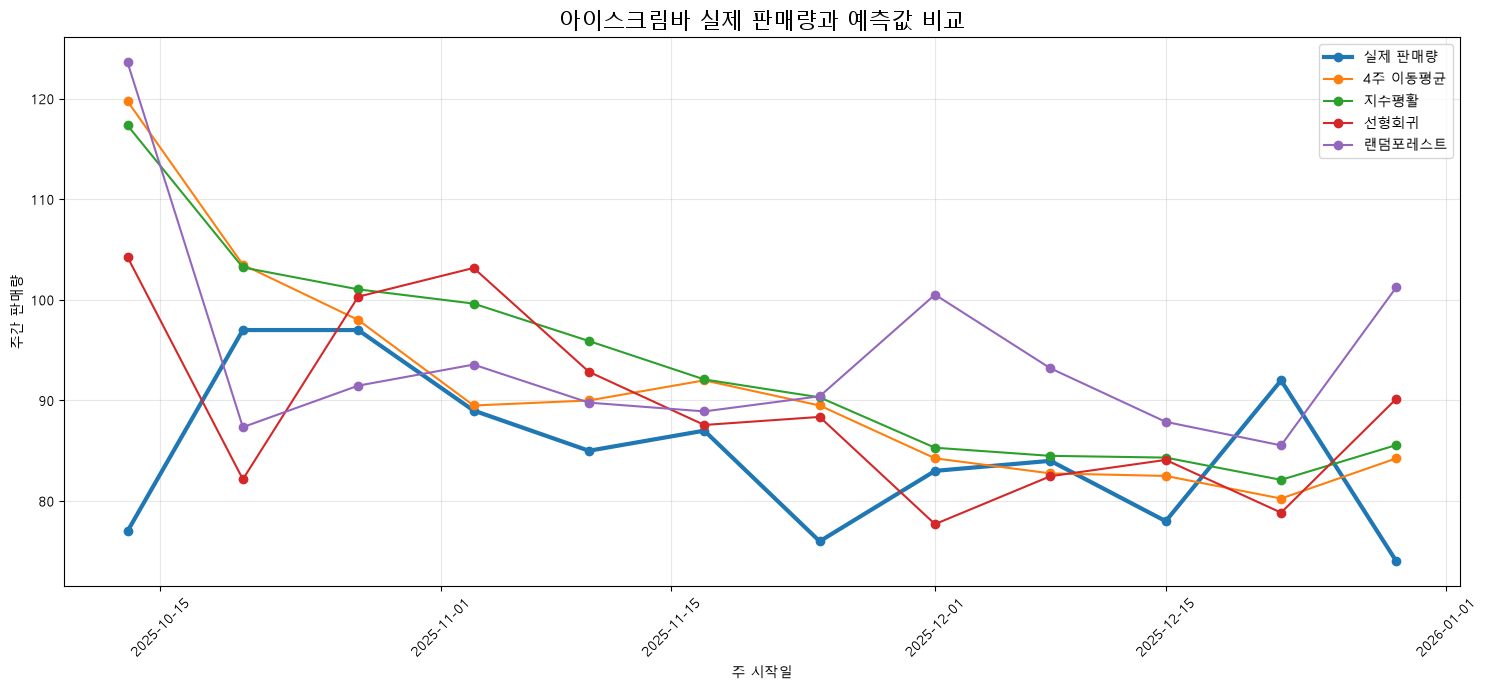


① 주별 오차
오차 = 실제 판매량 - 예측 판매량


,주 시작일,실제 판매량,4주 이동평균 오차,지수평활 오차,선형회귀 오차,랜덤포레스트 오차
0,2025-10-13,77,-42.75,-40.34,-27.26,-46.62
1,2025-10-20,97,-6.50,-6.22,14.84,9.65
2,2025-10-27,97,-1.00,-4.05,-3.32,5.53
3,2025-11-03,89,-0.50,-10.63,-14.17,-4.57
4,2025-11-10,85,-5.00,-10.91,-7.85,-4.78
5,2025-11-17,87,-5.00,-5.09,-0.56,-1.91
6,2025-11-24,76,-13.50,-14.31,-12.37,-14.42
7,2025-12-01,83,-1.25,-2.30,5.29,-17.52
8,2025-12-08,84,1.25,-0.50,1.53,-9.20
9,2025-12-15,78,-4.50,-6.32,-6.09,-9.87



② 예측 정확도 비교


,예측 방법,MAE,RMSE,MAPE(%)
0,4주 이동평균,8.60,14.05,10.72
1,지수평활,10.18,14.21,12.52
2,선형회귀,10.22,12.56,12.36
3,랜덤포레스트,13.15,17.86,16.39



③ MAPE가 가장 낮은 방법
가장 정확한 방법: 4주 이동평균
MAPE: 10.72 %

④ 가장 좋은 방법의 오차 표준편차
방법: 4주 이동평균
오차 표준편차: 12.49

MAPE가 가장 낮은 방법의 계산 과정


,실제값,예측값,오차,|오차|,오차²,절대백분율오차(%)
0,77,119.75,-42.75,42.75,1827.56,55.52
1,97,103.50,-6.50,6.50,42.25,6.70
2,97,98.00,-1.00,1.00,1.00,1.03
3,89,89.50,-0.50,0.50,0.25,0.56
4,85,90.00,-5.00,5.00,25.00,5.88
5,87,92.00,-5.00,5.00,25.00,5.75
6,76,89.50,-13.50,13.50,182.25,17.76
7,83,84.25,-1.25,1.25,1.56,1.51
8,84,82.75,1.25,1.25,1.56,1.49
9,78,82.50,-4.50,4.50,20.25,5.77



계산식
오차 = 실제 판매량 - 예측 판매량
MAE = |오차|의 평균
RMSE = √(오차²의 평균)
MAPE = |오차 / 실제 판매량|의 평균 × 100
오차 표준편차 = √((각 오차 - 평균 오차)²의 평균)


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor


# =========================
# 한글 폰트
# =========================
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


# =========================
# 0. 데이터 불러오기
# =========================
df = pd.read_excel(
    '[Step4]수강생예제실습.xlsx',
    sheet_name='주간수요'
)

# 아이스크림바 예측에 필요한 열만 사용
df = df[
    ['주 시작일', '월', '아이스크림바']
].copy()

df['주 시작일'] = pd.to_datetime(df['주 시작일'])

df = (
    df.sort_values('주 시작일')
      .reset_index(drop=True)
)


# =========================
# ① 마지막 12주는 테스트
# =========================
train = df.iloc[:-12].copy()
test = df.iloc[-12:].copy()

actual = test['아이스크림바'].values

print("학습 데이터:", len(train), "주")
print("테스트 데이터:", len(test), "주")


# ==================================================
# ②-1. 4주 이동평균
# ==================================================
history = list(train['아이스크림바'])

ma_pred = []

for i in range(len(test)):

    pred = np.mean(history[-4:])

    ma_pred.append(pred)

    # 다음 주를 예측하기 전에
    # 이번 주 실제값을 확인
    history.append(
        test.iloc[i]['아이스크림바']
    )


# ==================================================
# ②-2. 지수평활
# alpha = 0.35
# ==================================================
alpha = 0.35

history = list(train['아이스크림바'])

exp_pred = []

for i in range(len(test)):

    # 첫 판매량으로 초기화
    level = history[0]

    for value in history[1:]:

        level = (
            alpha * value
            + (1 - alpha) * level
        )

    exp_pred.append(level)

    # 실제값 확인 후 다음 주 예측
    history.append(
        test.iloc[i]['아이스크림바']
    )


# ==================================================
# 머신러닝용 데이터 생성 함수
#
# 입력변수
# - 1주 전 수요
# - 2주 전 수요
# - 최근 4주 평균
# - 월 정보
# ==================================================
def make_features(data):

    X = []
    y = []

    for i in range(4, len(data)):

        lag1 = data.iloc[i - 1]['아이스크림바']

        lag2 = data.iloc[i - 2]['아이스크림바']

        avg4 = (
            data.iloc[i - 4:i]['아이스크림바']
            .mean()
        )

        month = data.iloc[i]['월']

        X.append([
            lag1,
            lag2,
            avg4,
            month
        ])

        y.append(
            data.iloc[i]['아이스크림바']
        )

    return np.array(X), np.array(y)


# ==================================================
# ②-3. 선형회귀
# ==================================================
history_df = train.copy().reset_index(drop=True)

linear_pred = []

for i in range(len(test)):

    X_train, y_train = make_features(
        history_df
    )

    model = LinearRegression()

    model.fit(
        X_train,
        y_train
    )

    lag1 = history_df[
        '아이스크림바'
    ].iloc[-1]

    lag2 = history_df[
        '아이스크림바'
    ].iloc[-2]

    avg4 = history_df[
        '아이스크림바'
    ].iloc[-4:].mean()

    month = test.iloc[i]['월']

    X_next = np.array([
        [
            lag1,
            lag2,
            avg4,
            month
        ]
    ])

    pred = model.predict(X_next)[0]

    linear_pred.append(pred)

    # 실제값 확인 후 추가
    history_df = pd.concat(
        [
            history_df,
            test.iloc[[i]]
        ],
        ignore_index=True
    )


# ==================================================
# ②-4. 랜덤포레스트
# ==================================================
history_df = train.copy().reset_index(drop=True)

rf_pred = []

for i in range(len(test)):

    X_train, y_train = make_features(
        history_df
    )

    model = RandomForestRegressor(
        n_estimators=300,
        random_state=42
    )

    model.fit(
        X_train,
        y_train
    )

    lag1 = history_df[
        '아이스크림바'
    ].iloc[-1]

    lag2 = history_df[
        '아이스크림바'
    ].iloc[-2]

    avg4 = history_df[
        '아이스크림바'
    ].iloc[-4:].mean()

    month = test.iloc[i]['월']

    X_next = np.array([
        [
            lag1,
            lag2,
            avg4,
            month
        ]
    ])

    pred = model.predict(X_next)[0]

    rf_pred.append(pred)

    # 실제값 확인 후 추가
    history_df = pd.concat(
        [
            history_df,
            test.iloc[[i]]
        ],
        ignore_index=True
    )


# ==================================================
# ③ 실제값 + 네 예측값 그래프
# ==================================================
plt.figure(figsize=(15, 7))

plt.plot(
    test['주 시작일'],
    actual,
    marker='o',
    linewidth=3,
    label='실제 판매량'
)

plt.plot(
    test['주 시작일'],
    ma_pred,
    marker='o',
    label='4주 이동평균'
)

plt.plot(
    test['주 시작일'],
    exp_pred,
    marker='o',
    label='지수평활'
)

plt.plot(
    test['주 시작일'],
    linear_pred,
    marker='o',
    label='선형회귀'
)

plt.plot(
    test['주 시작일'],
    rf_pred,
    marker='o',
    label='랜덤포레스트'
)

plt.title(
    '아이스크림바 실제 판매량과 예측값 비교',
    fontsize=16
)

plt.xlabel('주 시작일')
plt.ylabel('주간 판매량')

plt.legend()
plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ==================================================
# ④ 주별 오차 계산
# 오차 = 실제 판매량 - 예측 판매량
# ==================================================
error_df = pd.DataFrame({

    '주 시작일':
        test['주 시작일'].values,

    '실제 판매량':
        actual,

    '4주 이동평균 오차':
        actual - np.array(ma_pred),

    '지수평활 오차':
        actual - np.array(exp_pred),

    '선형회귀 오차':
        actual - np.array(linear_pred),

    '랜덤포레스트 오차':
        actual - np.array(rf_pred)
})


# 보기 좋게 소수 둘째 자리
for col in error_df.columns[2:]:

    error_df[col] = (
        error_df[col]
        .round(2)
    )


print("\n① 주별 오차")
print("오차 = 실제 판매량 - 예측 판매량")

display(error_df)


# ==================================================
# 평가 함수
# ==================================================
def metrics(actual, pred):

    actual = np.array(actual)
    pred = np.array(pred)

    # 오차
    error = actual - pred

    # MAE
    mae = np.mean(
        np.abs(error)
    )

    # RMSE
    rmse = np.sqrt(
        np.mean(
            error ** 2
        )
    )

    # MAPE
    mape = np.mean(
        np.abs(
            error / actual
        )
    ) * 100

    return mae, rmse, mape


# ==================================================
# ⑤ 네 방법 MAE · RMSE · MAPE
# ==================================================
predictions = {

    '4주 이동평균':
        np.array(ma_pred),

    '지수평활':
        np.array(exp_pred),

    '선형회귀':
        np.array(linear_pred),

    '랜덤포레스트':
        np.array(rf_pred)
}


metric_result = []

for name, pred in predictions.items():

    mae, rmse, mape = metrics(
        actual,
        pred
    )

    metric_result.append([
        name,
        mae,
        rmse,
        mape
    ])


metric_df = pd.DataFrame(
    metric_result,
    columns=[
        '예측 방법',
        'MAE',
        'RMSE',
        'MAPE(%)'
    ]
)

metric_df[
    ['MAE', 'RMSE', 'MAPE(%)']
] = metric_df[
    ['MAE', 'RMSE', 'MAPE(%)']
].round(2)


print("\n② 예측 정확도 비교")

display(metric_df)


# ==================================================
# ⑥ MAPE 가장 낮은 방법
# ==================================================
best_idx = metric_df[
    'MAPE(%)'
].idxmin()

best_method = metric_df.loc[
    best_idx,
    '예측 방법'
]

best_mape = metric_df.loc[
    best_idx,
    'MAPE(%)'
]


print("\n③ MAPE가 가장 낮은 방법")

print(
    "가장 정확한 방법:",
    best_method
)

print(
    "MAPE:",
    best_mape,
    "%"
)


# ==================================================
# ⑦ 가장 좋은 방법의 오차 표준편차
# ==================================================
best_pred = predictions[
    best_method
]

best_error = (
    actual
    - best_pred
)

error_std = np.std(
    best_error,
    ddof=0
)


print("\n④ 가장 좋은 방법의 오차 표준편차")

print(
    "방법:",
    best_method
)

print(
    "오차 표준편차:",
    round(error_std, 2)
)


# ==================================================
# 계산 과정 확인
# ==================================================
check_df = pd.DataFrame({

    '실제값':
        actual,

    '예측값':
        np.round(
            best_pred,
            2
        ),

    '오차':
        np.round(
            best_error,
            2
        ),

    '|오차|':
        np.round(
            np.abs(best_error),
            2
        ),

    '오차²':
        np.round(
            best_error ** 2,
            2
        ),

    '절대백분율오차(%)':
        np.round(
            np.abs(
                best_error / actual
            ) * 100,
            2
        )
})


print("\nMAPE가 가장 낮은 방법의 계산 과정")

display(check_df)


# ==================================================
# 사용한 계산식
# ==================================================
print("\n계산식")

print(
    "오차 = 실제 판매량 - 예측 판매량"
)

print(
    "MAE = |오차|의 평균"
)

print(
    "RMSE = √(오차²의 평균)"
)

print(
    "MAPE = |오차 / 실제 판매량|의 평균 × 100"
)

print(
    "오차 표준편차 = √((각 오차 - 평균 오차)²의 평균)"
)

In [24]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression


# ==========================================
# 0. 데이터 불러오기
# ==========================================
df = pd.read_excel(
    '[Step4]수강생예제실습.xlsx',
    sheet_name='주간수요'
)

# 필요한 열만 사용
df = df[
    [
        '주 시작일',
        '아이스크림바',
        '생수 500ml'
    ]
].copy()

df['주 시작일'] = pd.to_datetime(df['주 시작일'])

df = (
    df.sort_values('주 시작일')
      .reset_index(drop=True)
)


# ==========================================
# 상품별 예측 + 평가 함수
# ==========================================
def evaluate_product(df, product):

    # --------------------------------------
    # 마지막 12주는 정답 확인용
    # --------------------------------------
    train = df.iloc[:-12].copy()
    test = df.iloc[-12:].copy()

    actual = test[product].to_numpy()


    # ======================================
    # 1. 최근 4주 평균 예측
    # ======================================
    history = list(train[product])

    moving_pred = []

    for i in range(len(test)):

        pred = np.mean(history[-4:])

        moving_pred.append(pred)

        # 한 주 예측 후 실제값 확인
        history.append(
            test.iloc[i][product]
        )

    moving_pred = np.array(moving_pred)


    # ======================================
    # 2. 선형회귀 예측
    # 입력 = 최근 4주 평균
    # ======================================
    model_data = train[[product]].copy()

    model_data['최근4주평균'] = (
        model_data[product]
        .shift(1)
        .rolling(4)
        .mean()
    )

    model_data = model_data.dropna()

    X_train = model_data[
        ['최근4주평균']
    ]

    y_train = model_data[product]

    model = LinearRegression()

    model.fit(
        X_train,
        y_train
    )


    # 한 주씩 예측
    history = list(train[product])

    linear_pred = []

    for i in range(len(test)):

        avg4 = np.mean(
            history[-4:]
        )

        X_next = pd.DataFrame({
            '최근4주평균': [avg4]
        })

        pred = model.predict(
            X_next
        )[0]

        linear_pred.append(pred)

        # 예측 후 실제값 확인
        history.append(
            test.iloc[i][product]
        )

    linear_pred = np.array(linear_pred)


    # ======================================
    # ① 주별 오차
    # 오차 = 실제 - 예측
    # ======================================
    moving_error = (
        actual - moving_pred
    )

    linear_error = (
        actual - linear_pred
    )


    error_table = pd.DataFrame({

        '주 시작일':
            test['주 시작일'].values,

        '실제 판매량':
            actual,

        '4주 평균 예측':
            np.round(moving_pred, 2),

        '4주 평균 오차':
            np.round(moving_error, 2),

        '선형회귀 예측':
            np.round(linear_pred, 2),

        '선형회귀 오차':
            np.round(linear_error, 2)
    })


    # ======================================
    # MAE / MAPE 계산 함수
    # ======================================
    def metrics(actual, pred):

        error = actual - pred

        # MAE
        mae = np.mean(
            np.abs(error)
        )

        # MAPE
        valid = actual != 0

        mape = (
            np.mean(
                np.abs(
                    error[valid]
                    / actual[valid]
                )
            )
            * 100
        )

        return mae, mape


    # 4주 평균
    moving_mae, moving_mape = metrics(
        actual,
        moving_pred
    )

    # 선형회귀
    linear_mae, linear_mape = metrics(
        actual,
        linear_pred
    )


    # ======================================
    # ② 정확도 비교표
    # ======================================
    metric_table = pd.DataFrame({

        '방법': [
            '최근 4주 평균',
            '선형회귀'
        ],

        'MAE': [
            moving_mae,
            linear_mae
        ],

        'MAPE(%)': [
            moving_mape,
            linear_mape
        ]
    })

    metric_table[
        ['MAE', 'MAPE(%)']
    ] = metric_table[
        ['MAE', 'MAPE(%)']
    ].round(2)


    # ======================================
    # 더 정확한 방법
    # MAPE 기준
    # ======================================
    if moving_mape < linear_mape:

        best_method = '최근 4주 평균'
        best_pred = moving_pred
        best_error = moving_error
        best_mape = moving_mape

    else:

        best_method = '선형회귀'
        best_pred = linear_pred
        best_error = linear_error
        best_mape = linear_mape


    # ======================================
    # ③ 오차 평균 + 표준편차
    # ======================================

    # 평균 오차
    error_mean = np.mean(
        best_error
    )

    # 오차 표준편차
    error_std = np.std(
        best_error,
        ddof=0
    )


    # ======================================
    # 출력
    # ======================================
    print("\n" + "=" * 60)
    print(product)
    print("=" * 60)


    print("\n① 주별 오차")
    print("오차 = 실제 판매량 - 예측 판매량")

    display(error_table)


    print("\n② MAE와 MAPE 비교")

    display(metric_table)


    print("더 정확한 방법(MAPE 기준):", best_method)
    print("MAPE:", round(best_mape, 2), "%")


    print("\n③ 더 정확한 방법의 오차")

    print(
        "평균 오차:",
        round(error_mean, 2)
    )

    print(
        "오차 표준편차:",
        round(error_std, 2)
    )


    return {
        '상품': product,
        '최적 방법': best_method,
        'MAPE': best_mape,
        '오차 평균': error_mean,
        '오차 표준편차': error_std
    }


# ==========================================
# 아이스크림바 평가
# ==========================================
ice_result = evaluate_product(
    df,
    '아이스크림바'
)


# ==========================================
# 생수 평가
# ==========================================
water_result = evaluate_product(
    df,
    '생수 500ml'
)


# ==========================================
# 예제 3
# 생수 vs 아이스크림바 MAPE 비교
# ==========================================
product_compare = pd.DataFrame(
    [
        ice_result,
        water_result
    ]
)

product_compare[
    [
        'MAPE',
        '오차 평균',
        '오차 표준편차'
    ]
] = product_compare[
    [
        'MAPE',
        '오차 평균',
        '오차 표준편차'
    ]
].round(2)


print("\n" + "=" * 60)
print("생수와 아이스크림바 예측 난이도 비교")
print("=" * 60)

display(product_compare)


# MAPE가 높은 상품 = 상대적으로 예측이 어려움
hardest = product_compare.loc[
    product_compare['MAPE'].idxmax()
]


print(
    "예측이 더 어려운 상품:",
    hardest['상품']
)

print(
    "MAPE:",
    hardest['MAPE'],
    "%"
)


# ==========================================
# 계산식
# ==========================================
print("\n" + "=" * 60)
print("계산식")
print("=" * 60)

print(
    "오차 = 실제 판매량 - 예측 판매량"
)

print(
    "MAE = Σ|실제 - 예측| / n"
)

print(
    "MAPE = Σ(|실제 - 예측| / 실제) / n × 100"
)

print(
    "평균 오차 = Σ(실제 - 예측) / n"
)

print(
    "오차 표준편차 = √[Σ(오차 - 평균오차)² / n]"
)


아이스크림바

① 주별 오차
오차 = 실제 판매량 - 예측 판매량


,주 시작일,실제 판매량,4주 평균 예측,4주 평균 오차,선형회귀 예측,선형회귀 오차
0,2025-10-13,77,119.75,-42.75,121.05,-44.05
1,2025-10-20,97,103.50,-6.50,107.37,-10.37
2,2025-10-27,97,98.00,-1.00,102.74,-5.74
3,2025-11-03,89,89.50,-0.50,95.59,-6.59
4,2025-11-10,85,90.00,-5.00,96.01,-11.01
5,2025-11-17,87,92.00,-5.00,97.69,-10.69
6,2025-11-24,76,89.50,-13.50,95.59,-19.59
7,2025-12-01,83,84.25,-1.25,91.17,-8.17
8,2025-12-08,84,82.75,1.25,89.91,-5.91
9,2025-12-15,78,82.50,-4.50,89.70,-11.70



② MAE와 MAPE 비교


,방법,MAE,MAPE(%)
0,최근 4주 평균,8.60,10.72
1,선형회귀,12.93,15.99


더 정확한 방법(MAPE 기준): 최근 4주 평균
MAPE: 10.72 %

③ 더 정확한 방법의 오차
평균 오차: -6.44
오차 표준편차: 12.49

생수 500ml

① 주별 오차
오차 = 실제 판매량 - 예측 판매량


...


② MAE와 MAPE 비교


,방법,MAE,MAPE(%)
0,최근 4주 평균,13.42,6.32
1,선형회귀,16.21,7.39


더 정확한 방법(MAPE 기준): 최근 4주 평균
MAPE: 6.32 %

③ 더 정확한 방법의 오차
평균 오차: 3.29
오차 표준편차: 15.34

생수와 아이스크림바 예측 난이도 비교


,상품,최적 방법,MAPE,오차 평균,오차 표준편차
0,아이스크림바,최근 4주 평균,10.72,-6.44,12.49
1,생수 500ml,최근 4주 평균,6.32,3.29,15.34


예측이 더 어려운 상품: 아이스크림바
MAPE: 10.72 %

계산식
오차 = 실제 판매량 - 예측 판매량
MAE = Σ|실제 - 예측| / n
MAPE = Σ(|실제 - 예측| / 실제) / n × 100
평균 오차 = Σ(실제 - 예측) / n
오차 표준편차 = √[Σ(오차 - 평균오차)² / n]


In [28]:
from scipy.stats import norm
import math

# ==========================================
# 입력값
# ==========================================
expected_demand = 60      # 다음 주 예상 판매량
error_std = 6             # 예측 오차 표준편차
service_level = 0.98      # 목표 서비스 수준 98%
order_qty = 300           # 1회 주문량


# ==========================================
# ① 서비스 수준 98%의 z값
# ==========================================
z = norm.ppf(service_level)

print("① 목표 서비스 수준의 z값")
print(f"서비스 수준 = {service_level * 100:.0f}%")
print(f"z = norm.ppf({service_level})")
print(f"z = {z:.4f}")


# ==========================================
# ② 안전재고
# 안전재고 = z × 표준편차
# ==========================================
safety_stock = z * error_std

print("\n② 안전재고")
print("안전재고 = z × 예측 오차 표준편차")
print(f"         = {z:.4f} × {error_std}")
print(f"         = {safety_stock:.2f}개")


# ==========================================
# ③ 재주문점 s
# 재주문점 = 다음 주 예상 판매량 + 안전재고
# ==========================================
reorder_point = expected_demand + safety_stock

print("\n③ 재주문점(s)")
print("재주문점 = 다음 주 예상 판매량 + 안전재고")
print(f"         = {expected_demand} + {safety_stock:.2f}")
print(f"         = {reorder_point:.2f}개")


# ==========================================
# ④ 목표재고 S
# 목표재고 = 재주문점 + 주문량
# ==========================================
target_stock = reorder_point + order_qty

print("\n④ 목표재고(S)")
print("목표재고 = 재주문점 + 1회 주문량")
print(f"         = {reorder_point:.2f} + {order_qty}")
print(f"         = {target_stock:.2f}개")


# ==========================================
# 정수 단위로 운영할 경우
# ==========================================
safety_stock_int = math.ceil(safety_stock)
reorder_point_int = math.ceil(reorder_point)
target_stock_int = math.ceil(target_stock)

print("\n" + "=" * 40)
print("최종 결과")
print("=" * 40)

print(f"z값             : {z:.4f}")
print(f"안전재고         : {safety_stock:.2f}개 → {safety_stock_int}개")
print(f"재주문점 s       : {reorder_point:.2f}개 → {reorder_point_int}개")
print(f"1회 주문량       : {order_qty}개")
print(f"목표재고 S       : {target_stock:.2f}개 → {target_stock_int}개")


# ==========================================
# (s, S) 정책 해석
# ==========================================
print("\n(s, S) 정책 기준")
print(f"→ 재고가 약 {reorder_point_int}개 수준이 되면 주문")
print(f"→ 목표재고는 약 {target_stock_int}개")

① 목표 서비스 수준의 z값
서비스 수준 = 98%
z = norm.ppf(0.98)
z = 2.0537

② 안전재고
안전재고 = z × 예측 오차 표준편차
         = 2.0537 × 6
         = 12.32개

③ 재주문점(s)
재주문점 = 다음 주 예상 판매량 + 안전재고
         = 60 + 12.32
         = 72.32개

④ 목표재고(S)
목표재고 = 재주문점 + 1회 주문량
         = 72.32 + 300
         = 372.32개

최종 결과
z값             : 2.0537
안전재고         : 12.32개 → 13개
재주문점 s       : 72.32개 → 73개
1회 주문량       : 300개
목표재고 S       : 372.32개 → 373개

(s, S) 정책 기준
→ 재고가 약 73개 수준이 되면 주문
→ 목표재고는 약 373개


In [30]:
from scipy.stats import norm
import math

# ==========================================
# 예제 1
# 예상 판매량 100개 / 표준편차 10개
# 서비스 수준 95%
# ==========================================

expected_demand = 100
error_std = 10
service_level = 0.95

# ① z값
z = norm.ppf(service_level)

# ② 안전재고
safety_stock = z * error_std

# ③ 재주문점
reorder_point = expected_demand + safety_stock

print("=" * 50)
print("예제 1")
print("=" * 50)

print(f"목표 서비스 수준 = {service_level * 100:.0f}%")
print(f"z값 = {z:.4f}")

print("\n안전재고")
print(f"= z × 표준편차")
print(f"= {z:.4f} × {error_std}")
print(f"= {safety_stock:.2f}개")

print("\n재주문점")
print(f"= 다음 주 예상 판매량 + 안전재고")
print(f"= {expected_demand} + {safety_stock:.2f}")
print(f"= {reorder_point:.2f}개")

print(f"\n정수 기준 재주문점 = {math.ceil(reorder_point)}개")


# ==========================================
# 예제 2
# 서비스 수준 90% → 99%
# 안전재고 증가량 비교
# ==========================================

service_90 = 0.90
service_99 = 0.99

z_90 = norm.ppf(service_90)
z_99 = norm.ppf(service_99)

safety_90 = z_90 * error_std
safety_99 = z_99 * error_std

reorder_90 = expected_demand + safety_90
reorder_99 = expected_demand + safety_99

increase = safety_99 - safety_90

print("\n" + "=" * 50)
print("예제 2")
print("=" * 50)

print("서비스 수준 90%")
print(f"z = {z_90:.4f}")
print(f"안전재고 = {z_90:.4f} × {error_std}")
print(f"         = {safety_90:.2f}개")
print(f"재주문점 = {expected_demand} + {safety_90:.2f}")
print(f"         = {reorder_90:.2f}개")

print("\n서비스 수준 99%")
print(f"z = {z_99:.4f}")
print(f"안전재고 = {z_99:.4f} × {error_std}")
print(f"         = {safety_99:.2f}개")
print(f"재주문점 = {expected_demand} + {safety_99:.2f}")
print(f"         = {reorder_99:.2f}개")

print("\n안전재고 증가량")
print(f"= {safety_99:.2f} - {safety_90:.2f}")
print(f"= {increase:.2f}개")


# ==========================================
# 예제 3
# 앞에서 사용한 자기 상품 값
# 예상 판매량 60개 / 표준편차 6개
# 서비스 수준 98%
# ==========================================

my_expected_demand = 60
my_error_std = 6
my_service_level = 0.98

my_z = norm.ppf(my_service_level)
my_safety_stock = my_z * my_error_std
my_reorder_point = my_expected_demand + my_safety_stock

print("\n" + "=" * 50)
print("예제 3")
print("=" * 50)

print(f"예상 판매량 = {my_expected_demand}개")
print(f"예측 오차 표준편차 = {my_error_std}개")
print(f"서비스 수준 = {my_service_level * 100:.0f}%")

print(f"\nz값 = {my_z:.4f}")

print("\n안전재고")
print(f"= {my_z:.4f} × {my_error_std}")
print(f"= {my_safety_stock:.2f}개")

print("\n재주문점")
print(f"= {my_expected_demand} + {my_safety_stock:.2f}")
print(f"= {my_reorder_point:.2f}개")

print(
    f"\n→ 예상 판매량 {my_expected_demand}개보다 "
    f"약 {my_safety_stock:.2f}개를 추가로 확보하는 기준입니다."
)
print(
    "→ 예측 오차에 대비한 안전재고를 포함하므로 "
    "상식적인 재주문점으로 볼 수 있습니다."
)

예제 1
목표 서비스 수준 = 95%
z값 = 1.6449

안전재고
= z × 표준편차
= 1.6449 × 10
= 16.45개

재주문점
= 다음 주 예상 판매량 + 안전재고
= 100 + 16.45
= 116.45개

정수 기준 재주문점 = 117개

예제 2
서비스 수준 90%
z = 1.2816
안전재고 = 1.2816 × 10
         = 12.82개
재주문점 = 100 + 12.82
         = 112.82개

서비스 수준 99%
z = 2.3263
안전재고 = 2.3263 × 10
         = 23.26개
재주문점 = 100 + 23.26
         = 123.26개

안전재고 증가량
= 23.26 - 12.82
= 10.45개

예제 3
예상 판매량 = 60개
예측 오차 표준편차 = 6개
서비스 수준 = 98%

z값 = 2.0537

안전재고
= 2.0537 × 6
= 12.32개

재주문점
= 60 + 12.32
= 72.32개

→ 예상 판매량 60개보다 약 12.32개를 추가로 확보하는 기준입니다.
→ 예측 오차에 대비한 안전재고를 포함하므로 상식적인 재주문점으로 볼 수 있습니다.


## 테스트

데이터 확인
수요 데이터: (624, 5)
SKU 수: 6
기간: 2023-01-02 00:00:00 ~ 2024-12-23 00:00:00


[STEP 1] 상품별 데이터 특성


,sku_id,상품명,평균주간수요,추세판단,평균대비_주당추세(%),계절성판단,최고수요월,최저수요월,월별수요격차(%),변동성,CV,이상치수,이상치비율(%)
0,SKU-01,생수 500ml,199.43,뚜렷한 추세 없음,-0.02,계절성 낮음,12,5,6.41,낮음,0.06,0,0.00
1,SKU-02,라면 5개입,119.62,뚜렷한 추세 없음,-0.02,약한 계절성,11,12,11.91,보통,0.10,2,1.92
2,SKU-03,아이스크림 바,110.90,뚜렷한 추세 없음,0.07,계절성 뚜렷,7,1,89.27,높음,0.32,13,12.50
3,SKU-04,주방세제 1L,79.80,뚜렷한 추세 없음,-0.03,계절성 낮음,2,9,9.82,낮음,0.09,2,1.92
4,SKU-05,커피믹스 100입,59.24,뚜렷한 추세 없음,-0.03,계절성 낮음,1,10,9.88,보통,0.11,0,0.00
5,SKU-06,화장지 30롤,99.41,뚜렷한 추세 없음,-0.02,약한 계절성,6,10,11.15,낮음,0.09,2,1.92


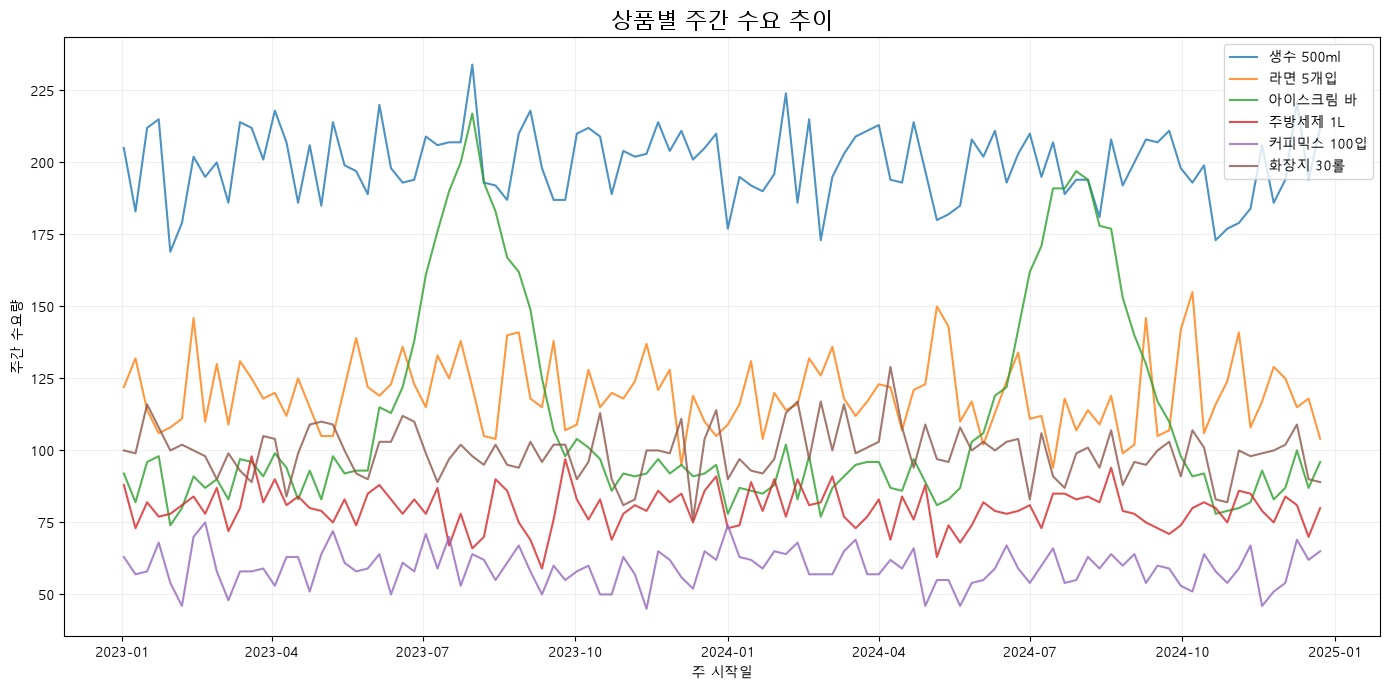

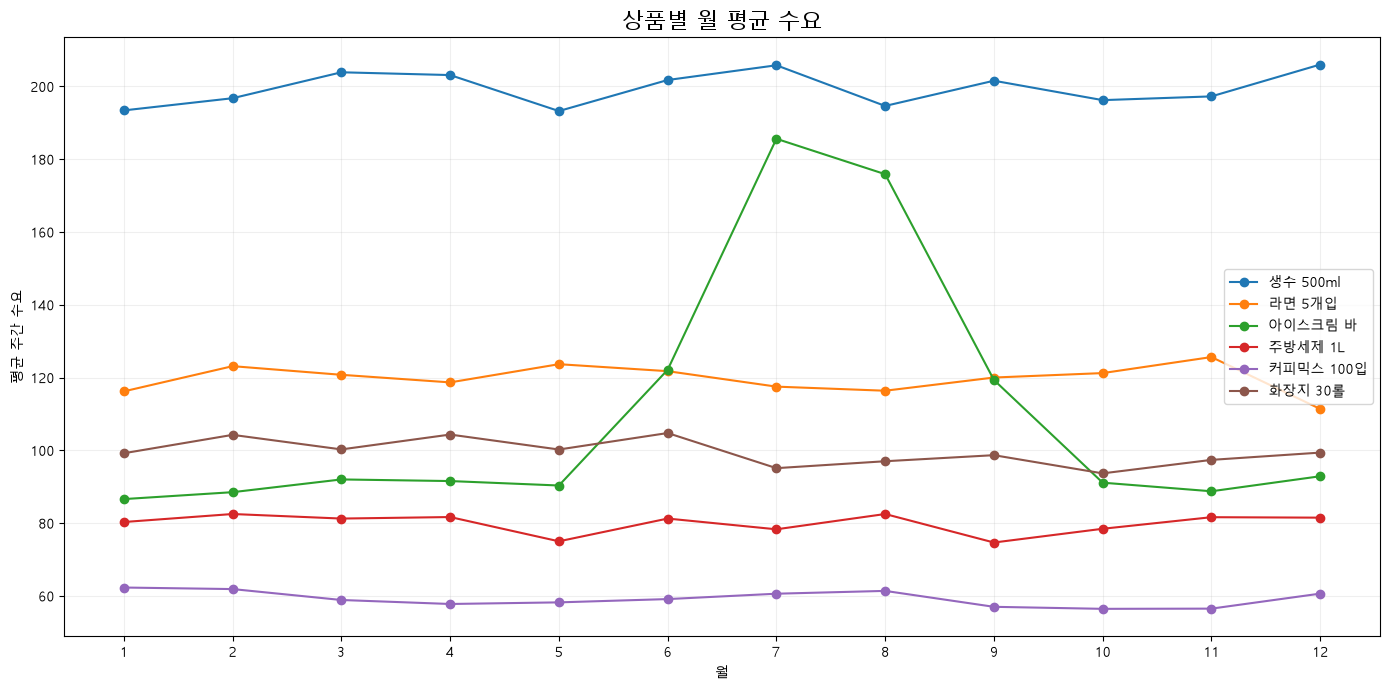

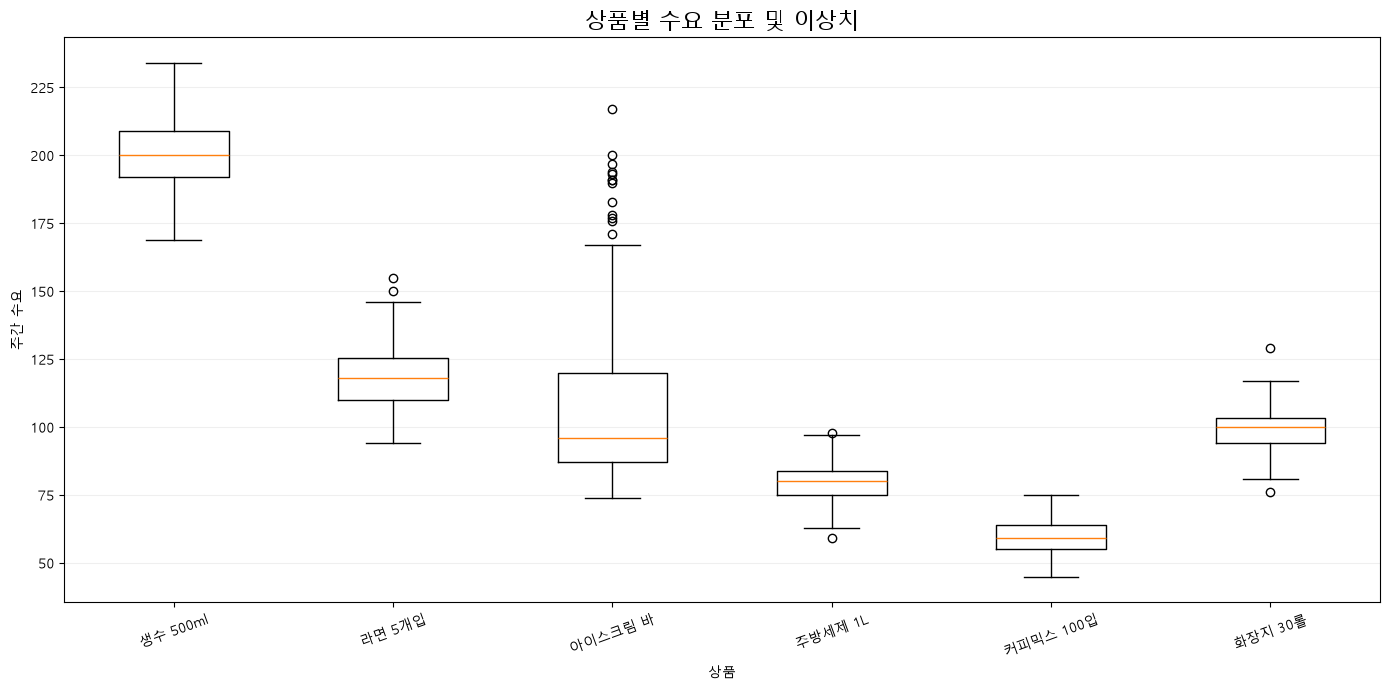



[STEP 2~3] 상품별 최적 예측모델


,sku_id,상품명,최적모델,MAE,RMSE,MAPE(%),sigma
0,SKU-01,생수 500ml,Huber,13.36,16.25,7.17,13.24
1,SKU-02,라면 5개입,SVR,12.25,17.43,9.25,15.98
2,SKU-03,아이스크림 바,DecisionTree,6.31,6.86,7.26,5.34
3,SKU-04,주방세제 1L,KNN,3.43,4.57,4.38,4.57
4,SKU-05,커피믹스 100입,AdaBoost,5.93,6.80,10.54,6.77
5,SKU-06,화장지 30롤,Huber,6.53,8.60,7.19,8.06




[STEP 4] 상품별 안전재고 / s / S


,sku_id,상품명,서비스수준,lead_time_weeks,sigma,z,안전재고,안전재고_정수,s,S
0,SKU-01,생수 500ml,0.99,1,13.24,2.33,30.79,31,226,716
1,SKU-02,라면 5개입,0.98,1,15.98,2.05,32.83,33,152,452
2,SKU-03,아이스크림 바,0.95,1,5.34,1.64,8.78,9,99,369
3,SKU-04,주방세제 1L,0.99,1,4.57,2.33,10.63,11,91,296
4,SKU-05,커피믹스 100입,0.98,1,6.77,2.05,13.91,14,75,370
5,SKU-06,화장지 30롤,0.99,1,8.06,2.33,18.74,19,119,369




[STEP 5] 13주 테스트 결과


...



[결론 참고] EOQ 기준 대비 개선 효과
※ 현행 운영 데이터가 아니라 EOQ를 기준으로 한 비교


,sku_id,sku_name,선택정책,EOQ_총비용,선택정책_총비용,EOQ대비_비용절감률(%),EOQ_FillRate,선택정책_FillRate,FillRate_변화(%p)
0,SKU-01,생수 500ml,GRID,601596,426144,29.16,0.91,0.98,6.60
1,SKU-02,라면 5개입,GRID,520125,481125,7.50,0.93,0.94,0.87
2,SKU-03,아이스크림 바,GRID,396382,372272,6.08,0.98,0.96,-2.01
3,SKU-04,주방세제 1L,GRID,669288,653645,2.34,0.95,0.95,0.10
4,SKU-05,커피믹스 100입,EOQ,598100,598100,0.00,0.97,0.97,0.00
5,SKU-06,화장지 30롤,GRID,1403224,798076,43.13,0.93,0.97,4.00




★★★★★ 보고서 작성용 최종 요약 ★★★★★


,sku_id,상품명,평균주간수요,표준편차,CV,변동성,추세기울기,평균대비_주당추세(%),추세판단,최고수요월,...,RMSE,MAPE(%),서비스수준,안전재고_정수,s,S,선택정책,선택정책_총비용,선택정책_FillRate,EOQ대비_비용절감률(%)
0,SKU-01,생수 500ml,199.43,12.45,0.06,낮음,-0.05,-0.02,뚜렷한 추세 없음,12,...,16.25,7.17,0.99,31,226,716,GRID,426144,0.98,29.16
1,SKU-02,라면 5개입,119.62,12.53,0.10,보통,-0.03,-0.02,뚜렷한 추세 없음,11,...,17.43,9.25,0.98,33,152,452,GRID,481125,0.94,7.50
2,SKU-03,아이스크림 바,110.90,35.82,0.32,높음,0.08,0.07,뚜렷한 추세 없음,7,...,6.86,7.26,0.95,9,99,369,GRID,372272,0.96,6.08
3,SKU-04,주방세제 1L,79.80,6.90,0.09,낮음,-0.02,-0.03,뚜렷한 추세 없음,2,...,4.57,4.38,0.99,11,91,296,GRID,653645,0.95,2.34
4,SKU-05,커피믹스 100입,59.24,6.38,0.11,보통,-0.02,-0.03,뚜렷한 추세 없음,1,...,6.80,10.54,0.98,14,75,370,EOQ,598100,0.97,0.00
5,SKU-06,화장지 30롤,99.41,8.85,0.09,낮음,-0.02,-0.02,뚜렷한 추세 없음,6,...,8.60,7.19,0.99,19,119,369,GRID,798076,0.97,43.13



저장 완료: 보고서용_분석결과.xlsx


In [13]:
# ============================================================
# 보고서용 결과 한번에 생성
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm

# ------------------------------------------------------------
# 한글 폰트
# ------------------------------------------------------------
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


# ============================================================
# 1. 파일 불러오기
# ============================================================

DEMAND_FILE = "demand_train.csv"
MASTER_FILE = "sku_master.csv"
RESULT_FILE = "최종_sS_모델비교.xlsx"


demand = pd.read_csv(DEMAND_FILE)
master = pd.read_csv(MASTER_FILE)

demand["week_start_date"] = pd.to_datetime(
    demand["week_start_date"]
)

demand = demand.sort_values(
    ["sku_id", "week_start_date"]
).reset_index(drop=True)


# 기존 모델 결과
final_result = pd.read_excel(
    RESULT_FILE,
    sheet_name="전체결과"
)

policy_result = pd.read_excel(
    RESULT_FILE,
    sheet_name="정책비교"
)


print("=" * 100)
print("데이터 확인")
print("=" * 100)

print("수요 데이터:", demand.shape)
print("SKU 수:", demand["sku_id"].nunique())
print("기간:",
      demand["week_start_date"].min(),
      "~",
      demand["week_start_date"].max())


# ============================================================
# 2. 상품별 데이터 특성
#    추세 / 계절성 / 변동성 / 이상치
# ============================================================

feature_rows = []


for sku_id in master["sku_id"]:

    df = (
        demand[
            demand["sku_id"] == sku_id
        ]
        .sort_values("week_start_date")
        .reset_index(drop=True)
        .copy()
    )

    sku_name = (
        master.loc[
            master["sku_id"] == sku_id,
            "sku_name"
        ]
        .iloc[0]
    )

    y = (
        df["weekly_demand_units"]
        .astype(float)
        .values
    )

    x = np.arange(len(y))


    # --------------------------------------------------------
    # 2-1. 추세
    # 선형 회귀선의 기울기
    # --------------------------------------------------------

    slope = np.polyfit(
        x,
        y,
        1
    )[0]


    mean_demand = np.mean(y)

    # 평균 대비 주당 기울기(%)
    if mean_demand != 0:
        slope_pct = (
            slope
            / mean_demand
            * 100
        )
    else:
        slope_pct = 0


    # 추세 판단 기준
    if slope_pct > 0.10:
        trend_result = "증가"

    elif slope_pct < -0.10:
        trend_result = "감소"

    else:
        trend_result = "뚜렷한 추세 없음"


    # --------------------------------------------------------
    # 2-2. 변동성
    # CV = 표준편차 / 평균
    # --------------------------------------------------------

    std_demand = np.std(
        y,
        ddof=1
    )

    if mean_demand != 0:

        cv = (
            std_demand
            / mean_demand
        )

    else:

        cv = 0


    if cv < 0.10:

        volatility = "낮음"

    elif cv < 0.20:

        volatility = "보통"

    else:

        volatility = "높음"


    # --------------------------------------------------------
    # 2-3. 이상치
    # IQR 방식
    # --------------------------------------------------------

    q1 = np.percentile(
        y,
        25
    )

    q3 = np.percentile(
        y,
        75
    )

    iqr = q3 - q1


    lower = (
        q1
        - 1.5 * iqr
    )

    upper = (
        q3
        + 1.5 * iqr
    )


    outlier_mask = (
        (y < lower)
        |
        (y > upper)
    )

    outlier_count = int(
        outlier_mask.sum()
    )


    outlier_pct = (
        outlier_count
        / len(y)
        * 100
    )


    # --------------------------------------------------------
    # 2-4. 계절성
    # 월별 평균 수요의 최대/최소 차이 확인
    # --------------------------------------------------------

    temp = df.copy()

    temp["month"] = (
        temp["week_start_date"]
        .dt.month
    )


    monthly_mean = (
        temp
        .groupby("month")[
            "weekly_demand_units"
        ]
        .mean()
    )


    max_month = int(
        monthly_mean.idxmax()
    )

    min_month = int(
        monthly_mean.idxmin()
    )


    max_month_demand = float(
        monthly_mean.max()
    )

    min_month_demand = float(
        monthly_mean.min()
    )


    # 월별 최대-최소 격차
    if mean_demand != 0:

        seasonal_range_pct = (
            (
                max_month_demand
                - min_month_demand
            )
            / mean_demand
            * 100
        )

    else:

        seasonal_range_pct = 0


    if seasonal_range_pct >= 20:

        seasonality = "계절성 뚜렷"

    elif seasonal_range_pct >= 10:

        seasonality = "약한 계절성"

    else:

        seasonality = "계절성 낮음"


    feature_rows.append({

        "sku_id":
            sku_id,

        "상품명":
            sku_name,

        "평균주간수요":
            mean_demand,

        "표준편차":
            std_demand,

        "CV":
            cv,

        "변동성":
            volatility,

        "추세기울기":
            slope,

        "평균대비_주당추세(%)":
            slope_pct,

        "추세판단":
            trend_result,

        "최고수요월":
            max_month,

        "최저수요월":
            min_month,

        "월별수요격차(%)":
            seasonal_range_pct,

        "계절성판단":
            seasonality,

        "이상치수":
            outlier_count,

        "이상치비율(%)":
            outlier_pct
    })


feature_df = pd.DataFrame(
    feature_rows
)


print("\n")
print("=" * 100)
print("[STEP 1] 상품별 데이터 특성")
print("=" * 100)


display(

    feature_df[
        [
            "sku_id",
            "상품명",
            "평균주간수요",
            "추세판단",
            "평균대비_주당추세(%)",
            "계절성판단",
            "최고수요월",
            "최저수요월",
            "월별수요격차(%)",
            "변동성",
            "CV",
            "이상치수",
            "이상치비율(%)"
        ]
    ]
    .round(2)

)


# ============================================================
# 3. 그래프 1
# 상품별 주간 수요 추세
# ============================================================

plt.figure(
    figsize=(14, 7)
)


for sku_id in master["sku_id"]:

    df = (
        demand[
            demand["sku_id"] == sku_id
        ]
        .sort_values("week_start_date")
    )

    sku_name = (
        master.loc[
            master["sku_id"] == sku_id,
            "sku_name"
        ]
        .iloc[0]
    )

    plt.plot(
        df["week_start_date"],
        df["weekly_demand_units"],
        label=sku_name,
        alpha=0.8
    )


plt.title(
    "상품별 주간 수요 추이",
    fontsize=16
)

plt.xlabel(
    "주 시작일"
)

plt.ylabel(
    "주간 수요량"
)

plt.legend()

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.show()


# ============================================================
# 4. 그래프 2
# 월별 평균 수요 → 계절성
# ============================================================

temp = demand.copy()

temp["month"] = (
    temp["week_start_date"]
    .dt.month
)


monthly = (
    temp
    .groupby(
        [
            "sku_id",
            "month"
        ]
    )[
        "weekly_demand_units"
    ]
    .mean()
    .reset_index()
)


plt.figure(
    figsize=(14, 7)
)


for sku_id in master["sku_id"]:

    d = monthly[
        monthly["sku_id"] == sku_id
    ]

    sku_name = (
        master.loc[
            master["sku_id"] == sku_id,
            "sku_name"
        ]
        .iloc[0]
    )

    plt.plot(
        d["month"],
        d["weekly_demand_units"],
        marker="o",
        label=sku_name
    )


plt.title(
    "상품별 월 평균 수요",
    fontsize=16
)

plt.xlabel(
    "월"
)

plt.ylabel(
    "평균 주간 수요"
)

plt.xticks(
    range(1, 13)
)

plt.legend()

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.show()


# ============================================================
# 5. 그래프 3
# Boxplot → 변동성 / 이상치
# ============================================================

plot_data = []

plot_labels = []


for sku_id in master["sku_id"]:

    d = (
        demand.loc[
            demand["sku_id"] == sku_id,
            "weekly_demand_units"
        ]
        .values
    )

    name = (
        master.loc[
            master["sku_id"] == sku_id,
            "sku_name"
        ]
        .iloc[0]
    )

    plot_data.append(
        d
    )

    plot_labels.append(
        name
    )


plt.figure(
    figsize=(14, 7)
)

plt.boxplot(
    plot_data,
    tick_labels=plot_labels,
    showfliers=True
)

plt.title(
    "상품별 수요 분포 및 이상치",
    fontsize=16
)

plt.xlabel(
    "상품"
)

plt.ylabel(
    "주간 수요"
)

plt.xticks(
    rotation=20
)

plt.grid(
    axis="y",
    alpha=0.2
)

plt.tight_layout()

plt.show()


# ============================================================
# 6. 모델 선정 결과
# ============================================================

print("\n")
print("=" * 100)
print("[STEP 2~3] 상품별 최적 예측모델")
print("=" * 100)


model_cols = [
    "sku_id",
    "상품명",
    "최적모델",
    "MAE",
    "RMSE",
    "MAPE(%)",
    "sigma"
]


available_model_cols = [
    col
    for col in model_cols
    if col in final_result.columns
]


display(
    final_result[
        available_model_cols
    ].round(2)
)


# ============================================================
# 7. 안전재고 계산
# ============================================================

inventory_result = (
    final_result
    .merge(
        master[
            [
                "sku_id",
                "lead_time_weeks"
            ]
        ],
        on="sku_id",
        how="left"
    )
)


# 서비스수준 → z
inventory_result["z"] = (

    inventory_result[
        "서비스수준"
    ]

    .apply(
        norm.ppf
    )
)


# 안전재고
inventory_result["안전재고"] = (

    inventory_result["z"]

    * inventory_result["sigma"]

    * np.sqrt(
        inventory_result[
            "lead_time_weeks"
        ]
    )
)


inventory_result[
    "안전재고_정수"
] = np.ceil(
    inventory_result[
        "안전재고"
    ]
).astype(int)


print("\n")
print("=" * 100)
print("[STEP 4] 상품별 안전재고 / s / S")
print("=" * 100)


display(

    inventory_result[
        [
            "sku_id",
            "상품명",
            "서비스수준",
            "lead_time_weeks",
            "sigma",
            "z",
            "안전재고",
            "안전재고_정수",
            "s",
            "S"
        ]
    ]
    .round(2)

)


# ============================================================
# 8. 정책 결과에서 상품별 최저비용 정책 추출
# ============================================================

best_policy = (

    policy_result

    .sort_values(
        "총비용"
    )

    .groupby(
        "sku_id",
        as_index=False
    )

    .first()
)


# 상품명 추가
best_policy = (
    best_policy
    .merge(
        master[
            [
                "sku_id",
                "sku_name"
            ]
        ],
        on="sku_id",
        how="left"
    )
)


# ============================================================
# 9. STEP 5
# 13주 검증 결과
# ============================================================

print("\n")
print("=" * 100)
print("[STEP 5] 13주 테스트 결과")
print("=" * 100)


step5_cols = [
    "sku_id",
    "sku_name",
    "policy",
    "service",
    "총비용",
    "주문비",
    "보관비",
    "품절비",
    "Fill_Rate"
]


available_step5_cols = [
    col
    for col in step5_cols
    if col in best_policy.columns
]


step5_df = (
    best_policy[
        available_step5_cols
    ]
    .copy()
)


if "service" in step5_df.columns:

    step5_df[
        "서비스수준(%)"
    ] = (
        step5_df[
            "service"
        ]
        * 100
    )


if "Fill_Rate" in step5_df.columns:

    step5_df[
        "Fill_Rate(%)"
    ] = (
        step5_df[
            "Fill_Rate"
        ]
        * 100
    )


display(
    step5_df.round(2)
)


# ============================================================
# 10. EOQ 대비 최적정책 비용 개선율
#
# 주의:
# 이것은 '현행 운영 대비'가 아니라
# EOQ 정책을 기준선으로 둔 비교임.
# ============================================================

eoq_policy = (
    policy_result[
        policy_result[
            "policy"
        ] == "EOQ"
    ]
    .sort_values(
        "총비용"
    )
    .groupby(
        "sku_id",
        as_index=False
    )
    .first()
)


selected_policy = (
    policy_result
    .sort_values(
        "총비용"
    )
    .groupby(
        "sku_id",
        as_index=False
    )
    .first()
)


comparison = (

    selected_policy[
        [
            "sku_id",
            "policy",
            "총비용",
            "Fill_Rate"
        ]
    ]

    .rename(
        columns={
            "policy":
                "선택정책",

            "총비용":
                "선택정책_총비용",

            "Fill_Rate":
                "선택정책_FillRate"
        }
    )

    .merge(

        eoq_policy[
            [
                "sku_id",
                "총비용",
                "Fill_Rate"
            ]
        ]
        .rename(
            columns={

                "총비용":
                    "EOQ_총비용",

                "Fill_Rate":
                    "EOQ_FillRate"
            }
        ),

        on="sku_id",

        how="left"
    )

    .merge(

        master[
            [
                "sku_id",
                "sku_name"
            ]
        ],

        on="sku_id",

        how="left"
    )
)


comparison[
    "EOQ대비_비용절감률(%)"
] = (

    (
        comparison[
            "EOQ_총비용"
        ]

        -

        comparison[
            "선택정책_총비용"
        ]
    )

    /

    comparison[
        "EOQ_총비용"
    ]

    * 100
)


comparison[
    "FillRate_변화(%p)"
] = (

    comparison[
        "선택정책_FillRate"
    ]

    -

    comparison[
        "EOQ_FillRate"
    ]

) * 100


print("\n")
print("=" * 100)
print("[결론 참고] EOQ 기준 대비 개선 효과")
print("※ 현행 운영 데이터가 아니라 EOQ를 기준으로 한 비교")
print("=" * 100)


display(

    comparison[
        [
            "sku_id",
            "sku_name",
            "선택정책",
            "EOQ_총비용",
            "선택정책_총비용",
            "EOQ대비_비용절감률(%)",
            "EOQ_FillRate",
            "선택정책_FillRate",
            "FillRate_변화(%p)"
        ]
    ]
    .round(2)

)


# ============================================================
# 11. 보고서 작성용 최종 요약
# ============================================================

report_summary = (

    feature_df

    .merge(

        inventory_result[
            [
                "sku_id",
                "최적모델",
                "MAE",
                "RMSE",
                "MAPE(%)",
                "서비스수준",
                "안전재고_정수",
                "s",
                "S"
            ]
        ],

        on="sku_id",

        how="left"
    )

    .merge(

        comparison[
            [
                "sku_id",
                "선택정책",
                "선택정책_총비용",
                "선택정책_FillRate",
                "EOQ대비_비용절감률(%)"
            ]
        ],

        on="sku_id",

        how="left"
    )
)


print("\n")
print("=" * 100)
print("★★★★★ 보고서 작성용 최종 요약 ★★★★★")
print("=" * 100)


display(
    report_summary.round(2)
)


# ============================================================
# 12. Excel로도 저장
# ============================================================

OUTPUT_FILE = "보고서용_분석결과.xlsx"


with pd.ExcelWriter(
    OUTPUT_FILE,
    engine="openpyxl"
) as writer:

    feature_df.to_excel(
        writer,
        sheet_name="데이터특성",
        index=False
    )

    inventory_result.to_excel(
        writer,
        sheet_name="안전재고_sS",
        index=False
    )

    step5_df.to_excel(
        writer,
        sheet_name="13주검증",
        index=False
    )

    comparison.to_excel(
        writer,
        sheet_name="EOQ대비비교",
        index=False
    )

    report_summary.to_excel(
        writer,
        sheet_name="보고서용요약",
        index=False
    )


print("\n저장 완료:", OUTPUT_FILE)

In [14]:
# ============================================================
# 2. 데이터 불러오기
# ============================================================

demand = pd.read_csv(
    DEMAND_FILE
)

master = pd.read_csv(
    MASTER_FILE
)


print("=" * 100)
print("[전처리 전 데이터 확인]")
print("=" * 100)

print("수요 데이터 :", demand.shape)
print("SKU 정보 :", master.shape)

print("\n수요 데이터 컬럼")
print(demand.columns.tolist())

print("\nSKU 데이터 컬럼")
print(master.columns.tolist())


# ============================================================
# 3. 데이터 전처리
# ============================================================

# ------------------------------------------------------------
# 3-1. 컬럼명 공백 제거
# ------------------------------------------------------------

demand.columns = (
    demand.columns
    .str.strip()
)

master.columns = (
    master.columns
    .str.strip()
)


# ------------------------------------------------------------
# 3-2. 날짜형 변환
# ------------------------------------------------------------

demand["week_start_date"] = pd.to_datetime(
    demand["week_start_date"],
    errors="coerce"
)


# ------------------------------------------------------------
# 3-3. 수요량 숫자형 변환
# ------------------------------------------------------------

demand["weekly_demand_units"] = pd.to_numeric(
    demand["weekly_demand_units"],
    errors="coerce"
)


# ------------------------------------------------------------
# 3-4. master 숫자형 컬럼 변환
# ------------------------------------------------------------

master_numeric_cols = [
    "minimum_order_quantity_units",
    "order_multiple_units",
    "target_service_level",
    "fixed_order_cost_krw_per_order",
    "unit_purchase_cost_krw",
    "weekly_holding_cost_krw_per_unit",
    "shortage_penalty_cost_krw_per_unit",
    "lead_time_weeks"
]


for col in master_numeric_cols:

    if col in master.columns:

        master[col] = pd.to_numeric(
            master[col],
            errors="coerce"
        )


# ============================================================
# 3-5. 결측치 확인
# ============================================================

print("\n")
print("=" * 100)
print("[결측치 확인]")
print("=" * 100)

print("\n수요 데이터 결측치")
print(
    demand.isnull().sum()
)

print("\nSKU master 결측치")
print(
    master.isnull().sum()
)


# ============================================================
# 3-6. 날짜 또는 SKU가 없는 행 제거
# ============================================================

before_rows = len(
    demand
)


demand = demand.dropna(
    subset=[
        "sku_id",
        "week_start_date"
    ]
).copy()


print(
    "\nSKU/날짜 결측 행 제거 :",
    before_rows - len(demand),
    "건"
)


# ============================================================
# 3-7. 중복 데이터 확인 및 처리
# ============================================================
# 동일 SKU + 동일 주차가 여러 건이면
# 주간수요를 합산
# ============================================================

duplicate_count = demand.duplicated(
    subset=[
        "sku_id",
        "week_start_date"
    ],
    keep=False
).sum()


print(
    "중복 SKU-주차 행 :",
    duplicate_count,
    "건"
)


if duplicate_count > 0:

    # demand의 기본 컬럼 보존
    agg_dict = {
        "weekly_demand_units": "sum"
    }

    # week 컬럼이 있으면 첫 값 보존
    if "week" in demand.columns:

        agg_dict["week"] = "first"


    demand = (
        demand
        .groupby(
            [
                "sku_id",
                "week_start_date"
            ],
            as_index=False
        )
        .agg(
            agg_dict
        )
    )


# ============================================================
# 3-8. 음수 수요 처리
# ============================================================
# 수요가 음수인 경우 정상 판매수요로 보기 어렵기 때문에
# 결측값으로 변경 후 보간
# ============================================================

negative_count = (
    demand[
        "weekly_demand_units"
    ] < 0
).sum()


print(
    "음수 수요 :",
    negative_count,
    "건"
)


demand.loc[
    demand[
        "weekly_demand_units"
    ] < 0,

    "weekly_demand_units"

] = np.nan


# ============================================================
# 3-9. SKU별 정렬
# ============================================================

demand = demand.sort_values(
    [
        "sku_id",
        "week_start_date"
    ]
).reset_index(
    drop=True
)


# ============================================================
# 3-10. 수요 결측치 보간
# ============================================================
# SKU 내부에서 선형보간
# 처음/마지막에 남은 결측치는 SKU 중앙값 사용
# ============================================================

missing_before = (
    demand[
        "weekly_demand_units"
    ]
    .isna()
    .sum()
)


demand[
    "weekly_demand_units"
] = (

    demand

    .groupby(
        "sku_id"
    )[
        "weekly_demand_units"
    ]

    .transform(
        lambda x:
            x.interpolate(
                method="linear",
                limit_direction="both"
            )
    )
)


# 혹시 보간 후에도 남으면 SKU 중앙값
demand[
    "weekly_demand_units"
] = (

    demand[
        "weekly_demand_units"
    ]

    .fillna(

        demand

        .groupby(
            "sku_id"
        )[
            "weekly_demand_units"
        ]

        .transform(
            "median"
        )
    )
)


missing_after = (
    demand[
        "weekly_demand_units"
    ]
    .isna()
    .sum()
)


print(
    "수요 결측치 처리 전 :",
    missing_before
)

print(
    "수요 결측치 처리 후 :",
    missing_after
)


# ============================================================
# 3-11. Master 중복 SKU 처리
# ============================================================

master_duplicate_count = (
    master[
        "sku_id"
    ]
    .duplicated()
    .sum()
)


print(
    "Master 중복 SKU :",
    master_duplicate_count,
    "건"
)


master = (
    master
    .drop_duplicates(
        subset=[
            "sku_id"
        ],
        keep="first"
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 3-12. Master 필수값 결측 확인
# ============================================================

required_master_cols = [

    "minimum_order_quantity_units",
    "order_multiple_units",
    "fixed_order_cost_krw_per_order",
    "weekly_holding_cost_krw_per_unit",
    "shortage_penalty_cost_krw_per_unit",
    "lead_time_weeks"
]


missing_master = (
    master[
        required_master_cols
    ]
    .isnull()
    .sum()
)


print("\n[Master 필수값 결측]")
print(
    missing_master
)


# ============================================================
# 3-13. 비정상 Master 값 검사
# ============================================================

print("\n[Master 비정상 값 확인]")


for col in [

    "minimum_order_quantity_units",
    "order_multiple_units",
    "fixed_order_cost_krw_per_order",
    "weekly_holding_cost_krw_per_unit",
    "shortage_penalty_cost_krw_per_unit"

]:

    bad_count = (
        master[col] < 0
    ).sum()

    print(
        col,
        ":",
        bad_count,
        "건"
    )


# lead time은 최소 1주로 설정
master[
    "lead_time_weeks"
] = (

    master[
        "lead_time_weeks"
    ]

    .clip(
        lower=1
    )
)


# MOQ / 주문단위도 최소 1
master[
    "minimum_order_quantity_units"
] = (

    master[
        "minimum_order_quantity_units"
    ]

    .clip(
        lower=1
    )
)


master[
    "order_multiple_units"
] = (

    master[
        "order_multiple_units"
    ]

    .clip(
        lower=1
    )
)


# ============================================================
# 3-14. SKU별 주차 개수 확인
# ============================================================

week_count = (

    demand

    .groupby(
        "sku_id"
    )

    .agg(

        관측주수=(
            "week_start_date",
            "count"
        ),

        시작일=(
            "week_start_date",
            "min"
        ),

        종료일=(
            "week_start_date",
            "max"
        )
    )

    .reset_index()
)


print("\n")
print("=" * 100)
print("[SKU별 관측기간]")
print("=" * 100)

display(
    week_count
)


# ============================================================
# 3-15. 주차 간격 이상 확인
# ============================================================

gap_rows = []


for sku_id, group in demand.groupby(
    "sku_id"
):

    group = (
        group
        .sort_values(
            "week_start_date"
        )
        .copy()
    )


    gap = (
        group[
            "week_start_date"
        ]
        .diff()
        .dt.days
    )


    abnormal_gap = (
        gap.dropna()
        != 7
    ).sum()


    gap_rows.append({

        "sku_id":
            sku_id,

        "비정상_주차간격_건수":
            int(
                abnormal_gap
            )
    })


gap_df = pd.DataFrame(
    gap_rows
)


print("\n[주차 간격 확인]")

display(
    gap_df
)


# ============================================================
# 3-16. 이상치 확인
# ============================================================
# 이상치는 실제 프로모션/계절성일 가능성이 있으므로
# 제거하지 않고 IQR 방식으로 탐지만 수행
# ============================================================

outlier_rows = []


for sku_id, group in demand.groupby(
    "sku_id"
):

    values = (
        group[
            "weekly_demand_units"
        ]
    )


    q1 = (
        values.quantile(
            0.25
        )
    )

    q3 = (
        values.quantile(
            0.75
        )
    )

    iqr = (
        q3
        - q1
    )


    lower = (
        q1
        - 1.5 * iqr
    )

    upper = (
        q3
        + 1.5 * iqr
    )


    outlier_mask = (

        (values < lower)

        |

        (values > upper)
    )


    outlier_count = int(
        outlier_mask.sum()
    )


    outlier_rows.append({

        "sku_id":
            sku_id,

        "Q1":
            q1,

        "Q3":
            q3,

        "IQR":
            iqr,

        "하한":
            lower,

        "상한":
            upper,

        "이상치수":
            outlier_count,

        "이상치비율(%)":
            (
                outlier_count
                / len(group)
                * 100
            )
    })


outlier_df = pd.DataFrame(
    outlier_rows
)


print("\n")
print("=" * 100)
print("[IQR 이상치 확인]")
print("=" * 100)

display(
    outlier_df.round(2)
)


# ============================================================
# 중요
# 이상치는 제거하지 않음
#
# 이유:
# - 실제 수요 급증일 수 있음
# - 프로모션/계절성 수요일 수 있음
# - 특히 아이스크림처럼 계절성이 강한 상품은
#   이상치 제거 시 실제 패턴까지 훼손할 위험이 있음
# ============================================================


# ============================================================
# 3-17. 최종 정렬 및 인덱스 초기화
# ============================================================

demand = (

    demand

    .sort_values(
        [
            "sku_id",
            "week_start_date"
        ]
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 3-18. 최종 전처리 결과
# ============================================================

print("\n")
print("=" * 100)
print("[전처리 완료]")
print("=" * 100)

print(
    "최종 수요 데이터 :",
    demand.shape
)

print(
    "최종 SKU 수 :",
    demand[
        "sku_id"
    ].nunique()
)

print(
    "결측 수요 :",
    demand[
        "weekly_demand_units"
    ]
    .isna()
    .sum()
)

print(
    "중복 SKU-주차 :",
    demand.duplicated(
        subset=[
            "sku_id",
            "week_start_date"
        ]
    ).sum()
)

print(
    "음수 수요 :",
    (
        demand[
            "weekly_demand_units"
        ] < 0
    ).sum()
)


# ============================================================
# 4. Feature 설정
# ============================================================

FEATURE_COLS = [
    "lag1",
    "lag2",
    "lag3",
    "lag4",
    "rolling4",
    "rolling8",
    "rolling_std4",
    "month",
    "week_sin",
    "week_cos",
    "trend"
]

# ============================================================
# 4. Feature 생성
# ============================================================

def make_features(df):

    df = df.copy()

    df = df.sort_values(
        "week_start_date"
    ).reset_index(drop=True)


    # --------------------------------------------------------
    # Lag
    # --------------------------------------------------------

    df["lag1"] = (
        df["weekly_demand_units"]
        .shift(1)
    )

    df["lag2"] = (
        df["weekly_demand_units"]
        .shift(2)
    )

    df["lag3"] = (
        df["weekly_demand_units"]
        .shift(3)
    )

    df["lag4"] = (
        df["weekly_demand_units"]
        .shift(4)
    )


    # --------------------------------------------------------
    # 이동평균
    # --------------------------------------------------------

    df["rolling4"] = (
        df["weekly_demand_units"]
        .shift(1)
        .rolling(4)
        .mean()
    )

    df["rolling8"] = (
        df["weekly_demand_units"]
        .shift(1)
        .rolling(8)
        .mean()
    )


    # 최근 4주 변동성
    df["rolling_std4"] = (
        df["weekly_demand_units"]
        .shift(1)
        .rolling(4)
        .std()
    )


    # --------------------------------------------------------
    # 시간 정보
    # --------------------------------------------------------

    df["month"] = (
        df["week_start_date"]
        .dt.month
    )


    week_num = (
        df["week_start_date"]
        .dt.isocalendar()
        .week
        .astype(int)
    )


    # 연간 계절성
    df["week_sin"] = np.sin(
        2 * np.pi * week_num / 52
    )

    df["week_cos"] = np.cos(
        2 * np.pi * week_num / 52
    )


    # 시간 추세
    df["trend"] = np.arange(
        len(df)
    )


    return df


# ============================================================
# 5. 다음 주 Feature
# ============================================================

def make_next_feature(
    history,
    next_date
):

    week_num = int(
        next_date
        .isocalendar()
        .week
    )


    recent4 = (
        history[
            "weekly_demand_units"
        ]
        .iloc[-4:]
    )


    X_next = pd.DataFrame({

        "lag1": [
            history[
                "weekly_demand_units"
            ].iloc[-1]
        ],

        "lag2": [
            history[
                "weekly_demand_units"
            ].iloc[-2]
        ],

        "lag3": [
            history[
                "weekly_demand_units"
            ].iloc[-3]
        ],

        "lag4": [
            history[
                "weekly_demand_units"
            ].iloc[-4]
        ],

        "rolling4": [
            recent4.mean()
        ],

        "rolling8": [
            history[
                "weekly_demand_units"
            ]
            .iloc[-8:]
            .mean()
        ],

        "rolling_std4": [
            recent4.std()
        ],

        "month": [
            next_date.month
        ],

        "week_sin": [
            np.sin(
                2
                * np.pi
                * week_num
                / 52
            )
        ],

        "week_cos": [
            np.cos(
                2
                * np.pi
                * week_num
                / 52
            )
        ],

        "trend": [
            len(history)
        ]
    })


    return X_next


# ============================================================
# 6. 미래 N주 재귀 예측
# ============================================================
#
# 중요
#
# 92주를 예측한 뒤
# 92주 예측값을 93주 입력으로 사용
#
# → 실제 미래값을 사용하지 않음
# ============================================================

def recursive_forecast(
    model,
    history,
    periods,
    future_dates=None
):

    history = history.copy()

    predictions = []
    dates = []


    last_date = (
        history[
            "week_start_date"
        ].iloc[-1]
    )


    for i in range(periods):

        # 날짜
        if future_dates is None:

            next_date = (
                last_date
                + pd.Timedelta(
                    weeks=i + 1
                )
            )

        else:

            next_date = pd.to_datetime(
                future_dates[i]
            )


        # Feature
        X_next = make_next_feature(
            history,
            next_date
        )


        # 예측
        pred = float(
            model.predict(
                X_next
            )[0]
        )


        # 수요 음수 방지
        pred = max(
            pred,
            0
        )


        predictions.append(
            pred
        )

        dates.append(
            next_date
        )


        # 예측값을 다음 주 lag용으로 추가
        new_row = pd.DataFrame({

            "week_start_date": [
                next_date
            ],

            "weekly_demand_units": [
                pred
            ]
        })


        history = pd.concat(
            [
                history,
                new_row
            ],
            ignore_index=True
        )


    return (
        np.array(predictions),
        dates
    )


# ============================================================
# 7. MAPE
# ============================================================

def calc_mape(
    actual,
    pred
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    pred = np.asarray(
        pred,
        dtype=float
    )


    mask = (
        actual != 0
    )


    return (
        np.mean(
            np.abs(
                (
                    actual[mask]
                    - pred[mask]
                )
                / actual[mask]
            )
        )
        * 100
    )


# ============================================================
# 8. 비교할 예측 모델
# ============================================================

def get_candidate_models():

    models = {

        # ====================================================
        # 1. Linear Regression
        # ====================================================

        "LinearRegression":
            LinearRegression(),


        # ====================================================
        # 2. Ridge
        # ====================================================

        "Ridge":
            Pipeline([

                (
                    "scaler",
                    StandardScaler()
                ),

                (
                    "model",
                    Ridge(
                        alpha=1.0
                    )
                )
            ]),


        # ====================================================
        # 3. ElasticNet
        # ====================================================

        "ElasticNet":
            Pipeline([

                (
                    "scaler",
                    StandardScaler()
                ),

                (
                    "model",
                    ElasticNet(
                        alpha=0.05,
                        l1_ratio=0.5,
                        max_iter=5000,
                        random_state=42
                    )
                )
            ]),


        # ====================================================
        # 4. Huber
        # 이상치에 조금 더 강한 선형회귀
        # ====================================================

        "Huber":
            Pipeline([

                (
                    "scaler",
                    StandardScaler()
                ),

                (
                    "model",
                    HuberRegressor(
                        max_iter=1000
                    )
                )
            ]),


        # ====================================================
        # 5. KNN
        # ====================================================

        "KNN":
            Pipeline([

                (
                    "scaler",
                    StandardScaler()
                ),

                (
                    "model",
                    KNeighborsRegressor(
                        n_neighbors=5,
                        weights="distance"
                    )
                )
            ]),


        # ====================================================
        # 6. SVR
        # ====================================================

        "SVR":
            Pipeline([

                (
                    "scaler",
                    StandardScaler()
                ),

                (
                    "model",
                    SVR(
                        kernel="rbf",
                        C=10,
                        epsilon=0.1,
                        gamma="scale"
                    )
                )
            ]),


        # ====================================================
        # 7. Decision Tree
        # ====================================================

        "DecisionTree":
            DecisionTreeRegressor(

                max_depth=5,

                min_samples_leaf=3,

                random_state=42
            ),


        # ====================================================
        # 8. Random Forest
        # ====================================================

        "RandomForest":
            RandomForestRegressor(

                n_estimators=150,

                max_depth=None,

                min_samples_leaf=2,

                random_state=42,

                n_jobs=-1
            ),


        # ====================================================
        # 9. Extra Trees
        # ====================================================

        "ExtraTrees":
            ExtraTreesRegressor(

                n_estimators=150,

                min_samples_leaf=2,

                random_state=42,

                n_jobs=-1
            ),


        # ====================================================
        # 10. Gradient Boosting
        # ====================================================

        "GradientBoosting":
            GradientBoostingRegressor(

                n_estimators=150,

                learning_rate=0.05,

                max_depth=3,

                random_state=42
            ),


        # ====================================================
        # 11. Hist Gradient Boosting
        # ====================================================

        "HistGradientBoosting":
            HistGradientBoostingRegressor(

                learning_rate=0.05,

                max_iter=200,

                max_leaf_nodes=15,

                l2_regularization=1,

                random_state=42
            ),


        # ====================================================
        # 12. AdaBoost
        # ====================================================

        "AdaBoost":
            AdaBoostRegressor(

                n_estimators=150,

                learning_rate=0.05,

                random_state=42
            )
    }


    return models


# ============================================================
# 9. 모델 비교
#
# 91주 학습
# ↓
# 92~104주 13주 재귀예측
# ↓
# MAPE 가장 작은 모델 선택
# ============================================================

def select_best_model(
    train_raw,
    valid_raw
):

    train_feature = (
        make_features(
            train_raw
        )
        .dropna()
        .copy()
    )


    X_train = (
        train_feature[
            FEATURE_COLS
        ]
    )


    y_train = (
        train_feature[
            "weekly_demand_units"
        ]
    )


    actual = (
        valid_raw[
            "weekly_demand_units"
        ]
        .to_numpy(
            dtype=float
        )
    )


    valid_dates = (
        valid_raw[
            "week_start_date"
        ]
        .tolist()
    )


    model_results = []


    best_name = None
    best_model = None
    best_pred = None

    best_mape = np.inf


    models = get_candidate_models()


    for name, model in models.items():

        try:

            fitted_model = clone(
                model
            )


            # ----------------------------------------------
            # 학습
            # ----------------------------------------------

            fitted_model.fit(
                X_train,
                y_train
            )


            # ----------------------------------------------
            # 13주 재귀 예측
            # ----------------------------------------------

            pred, _ = recursive_forecast(

                model=
                    fitted_model,

                history=
                    train_raw[
                        [
                            "week_start_date",
                            "weekly_demand_units"
                        ]
                    ],

                periods=
                    VALID_WEEKS,

                future_dates=
                    valid_dates
            )


            # ----------------------------------------------
            # 정확도
            # ----------------------------------------------

            mae = (
                mean_absolute_error(
                    actual,
                    pred
                )
            )


            rmse = np.sqrt(
                mean_squared_error(
                    actual,
                    pred
                )
            )


            mape = calc_mape(
                actual,
                pred
            )


            model_results.append({

                "모델":
                    name,

                "MAE":
                    mae,

                "RMSE":
                    rmse,

                "MAPE(%)":
                    mape
            })


            print(
                f"{name:25s}"
                f" MAPE = "
                f"{mape:.2f}%"
            )


            # ----------------------------------------------
            # 최적 모델 저장
            # ----------------------------------------------

            if mape < best_mape:

                best_mape = (
                    mape
                )

                best_name = (
                    name
                )

                best_model = (
                    fitted_model
                )

                best_pred = (
                    pred
                )


        except Exception as e:

            print(
                name,
                "실패:",
                e
            )


    result_df = pd.DataFrame(
        model_results
    )


    result_df = (
        result_df
        .sort_values(
            "MAPE(%)"
        )
        .reset_index(
            drop=True
        )
    )


    return (
        best_name,
        best_model,
        best_pred,
        result_df
    )


# ============================================================
# 10. 주문량 보정
# ============================================================

def adjust_order_quantity(
    quantity,
    moq,
    order_multiple
):

    if quantity <= 0:

        return 0


    # 최소주문량
    quantity = max(
        quantity,
        moq
    )


    # 주문단위
    quantity = (
        math.ceil(
            quantity
            / order_multiple
        )
        * order_multiple
    )


    return int(
        quantity
    )


# ============================================================
# 11. EOQ
# ============================================================

def calculate_eoq(
    weekly_demand,
    fixed_order_cost,
    weekly_holding_cost
):

    annual_demand = (
        weekly_demand
        * 52
    )


    annual_holding_cost = (
        weekly_holding_cost
        * 52
    )


    if annual_holding_cost <= 0:

        return 0


    return np.sqrt(

        (
            2
            * annual_demand
            * fixed_order_cost
        )

        /

        annual_holding_cost
    )


# ============================================================
# 12. s, S 계산
# ============================================================

def calculate_sS(
    method,
    expected_weekly_demand,
    sigma,
    service_level,
    lead_time,
    moq,
    order_multiple,
    eoq_q=None,
    coverage_weeks=None
):

    d = max(
        float(
            expected_weekly_demand
        ),
        0
    )


    # 서비스 수준 → z
    z = norm.ppf(
        service_level
    )


    # ========================================================
    # 안전재고
    # ========================================================

    safety_stock = (

        z
        * sigma
        * np.sqrt(
            lead_time
        )
    )


    # ========================================================
    # 재주문점 s
    # ========================================================

    s = (

        d
        * lead_time

        +

        safety_stock
    )


    # ========================================================
    # 방법 A
    # EOQ
    # ========================================================

    if method == "EOQ":

        gap = adjust_order_quantity(

            eoq_q,

            moq,

            order_multiple
        )


        S = (
            s
            + gap
        )


    # ========================================================
    # 방법 B
    # Order-up-to
    # ========================================================

    elif method == "ORDER_UP_TO":

        protection_period = (
            lead_time
            + REVIEW_PERIOD
        )


        protection_safety = (

            z
            * sigma
            * np.sqrt(
                protection_period
            )
        )


        raw_S = (

            d
            * protection_period

            +

            protection_safety
        )


        raw_gap = max(

            raw_S
            - s,

            moq
        )


        gap = adjust_order_quantity(

            raw_gap,

            moq,

            order_multiple
        )


        S = (
            s
            + gap
        )


    # ========================================================
    # 방법 C
    # Grid Search
    # ========================================================

    elif method == "GRID":

        raw_gap = (

            d
            * coverage_weeks
        )


        gap = adjust_order_quantity(

            raw_gap,

            moq,

            order_multiple
        )


        S = (
            s
            + gap
        )


    else:

        raise ValueError(
            "정책 오류"
        )


    return {

        "s":
            float(s),

        "S":
            float(S),

        "z":
            float(z),

        "safety_stock":
            float(
                safety_stock
            )
    }


# ============================================================
# 13. 재고정책 시뮬레이션
# ============================================================

def simulate_policy(
    actual_demand,
    forecast_reference,
    method,
    sigma,
    service_level,
    sku_info,
    eoq_q=None,
    coverage_weeks=None
):

    actual_demand = np.asarray(
        actual_demand,
        dtype=float
    )


    # --------------------------------------------------------
    # master 정보
    # --------------------------------------------------------

    lead_time = int(
        sku_info[
            "lead_time_weeks"
        ]
    )


    moq = int(
        sku_info[
            "minimum_order_quantity_units"
        ]
    )


    order_multiple = int(
        sku_info[
            "order_multiple_units"
        ]
    )


    fixed_order_cost = float(
        sku_info[
            "fixed_order_cost_krw_per_order"
        ]
    )


    holding_cost = float(
        sku_info[
            "weekly_holding_cost_krw_per_unit"
        ]
    )


    shortage_cost = float(
        sku_info[
            "shortage_penalty_cost_krw_per_unit"
        ]
    )


    # --------------------------------------------------------
    # s, S
    # --------------------------------------------------------

    levels = calculate_sS(

        method=
            method,

        expected_weekly_demand=
            forecast_reference,

        sigma=
            sigma,

        service_level=
            service_level,

        lead_time=
            lead_time,

        moq=
            moq,

        order_multiple=
            order_multiple,

        eoq_q=
            eoq_q,

        coverage_weeks=
            coverage_weeks
    )


    s = levels["s"]
    S = levels["S"]


    # --------------------------------------------------------
    # 모든 정책 동일 시작재고
    # --------------------------------------------------------

    on_hand = math.ceil(

        forecast_reference

        * (
            lead_time
            + 1
        )
    )


    scheduled_arrivals = {}


    total_order_cost = 0
    total_holding_cost = 0
    total_shortage_cost = 0

    total_shortage_units = 0


    # ========================================================
    # 13주 시뮬레이션
    # ========================================================

    for t, demand_t in enumerate(
        actual_demand
    ):


        # ----------------------------------------------------
        # 입고
        # ----------------------------------------------------

        arrival = (
            scheduled_arrivals
            .pop(
                t,
                0
            )
        )


        on_hand += (
            arrival
        )


        # ----------------------------------------------------
        # 미입고 주문
        # ----------------------------------------------------

        on_order = sum(
            scheduled_arrivals
            .values()
        )


        # ----------------------------------------------------
        # Inventory Position
        # ----------------------------------------------------

        inventory_position = (

            on_hand
            + on_order
        )


        # ----------------------------------------------------
        # s 이하 → S까지 주문
        # ----------------------------------------------------

        if inventory_position <= s:


            raw_order = (

                S
                - inventory_position
            )


            order_qty = adjust_order_quantity(

                raw_order,

                moq,

                order_multiple
            )


            if order_qty > 0:


                arrival_week = (

                    t
                    + lead_time
                )


                scheduled_arrivals[
                    arrival_week
                ] = (

                    scheduled_arrivals
                    .get(
                        arrival_week,
                        0
                    )

                    +

                    order_qty
                )


                total_order_cost += (
                    fixed_order_cost
                )


        # ----------------------------------------------------
        # 실제 수요
        # ----------------------------------------------------

        shortage = max(

            demand_t
            - on_hand,

            0
        )


        on_hand = max(

            on_hand
            - demand_t,

            0
        )


        # ----------------------------------------------------
        # 비용
        # ----------------------------------------------------

        total_holding_cost += (

            on_hand
            * holding_cost
        )


        total_shortage_cost += (

            shortage
            * shortage_cost
        )


        total_shortage_units += (
            shortage
        )


    # ========================================================
    # 결과
    # ========================================================

    total_cost = (

        total_order_cost

        +

        total_holding_cost

        +

        total_shortage_cost
    )


    total_demand = (
        actual_demand.sum()
    )


    if total_demand > 0:

        fill_rate = (

            1

            -

            (
                total_shortage_units
                / total_demand
            )
        )

    else:

        fill_rate = 1


    return {

        "s":
            s,

        "S":
            S,

        "총비용":
            total_cost,

        "주문비":
            total_order_cost,

        "보관비":
            total_holding_cost,

        "품절비":
            total_shortage_cost,

        "Fill_Rate":
            fill_rate
    }


# ============================================================
# 14. 상품 한 개 분석
# ============================================================

def analyze_sku(
    sku_id
):

    print("\n")
    print("=" * 90)


    sku_df = (

        demand[
            demand["sku_id"]
            == sku_id
        ]

        .sort_values(
            "week_start_date"
        )

        .reset_index(
            drop=True
        )
    )


    sku_info = (

        master[
            master["sku_id"]
            == sku_id
        ]

        .iloc[0]
    )


    sku_name = (
        sku_info[
            "sku_name"
        ]
    )


    print(
        f"{sku_id} | {sku_name}"
    )

    print("=" * 90)


    # ========================================================
    # 15. 91주 / 13주
    # ========================================================

    train_raw = (
        sku_df
        .iloc[
            :-VALID_WEEKS
        ]
        .copy()
    )


    valid_raw = (
        sku_df
        .iloc[
            -VALID_WEEKS:
        ]
        .copy()
    )


    print(
        "학습:",
        len(train_raw),
        "주"
    )

    print(
        "검증:",
        len(valid_raw),
        "주"
    )


    # ========================================================
    # 16. 모델 비교
    # ========================================================

    (
        best_model_name,
        best_model,
        valid_pred,
        model_compare

    ) = select_best_model(

        train_raw,
        valid_raw
    )


    print("\n[모델 순위]")

    display(
        model_compare
        .round(2)
    )


    print(
        "\n최적 모델:",
        best_model_name
    )


    # ========================================================
    # 17. 최적모델 정확도
    # ========================================================

    actual = (

        valid_raw[
            "weekly_demand_units"
        ]

        .to_numpy(
            dtype=float
        )
    )


    errors = (

        actual
        - valid_pred
    )


    mae = mean_absolute_error(
        actual,
        valid_pred
    )


    rmse = np.sqrt(
        mean_squared_error(
            actual,
            valid_pred
        )
    )


    mape = calc_mape(
        actual,
        valid_pred
    )


    sigma = np.std(
        errors,
        ddof=0
    )


    print(
        f"MAPE = {mape:.2f}%"
    )

    print(
        f"오차 표준편차 = "
        f"{sigma:.2f}"
    )


    # ========================================================
    # 18. SKU 비용 정보
    # ========================================================

    fixed_order_cost = float(

        sku_info[
            "fixed_order_cost_krw_per_order"
        ]
    )


    holding_cost = float(

        sku_info[
            "weekly_holding_cost_krw_per_unit"
        ]
    )


    moq = int(

        sku_info[
            "minimum_order_quantity_units"
        ]
    )


    order_multiple = int(

        sku_info[
            "order_multiple_units"
        ]
    )


    # ========================================================
    # 19. 검증 EOQ
    # ========================================================

    validation_eoq = calculate_eoq(

        weekly_demand=
            train_raw[
                "weekly_demand_units"
            ].mean(),

        fixed_order_cost=
            fixed_order_cost,

        weekly_holding_cost=
            holding_cost
    )


    validation_eoq = adjust_order_quantity(

        validation_eoq,

        moq,

        order_multiple
    )


    # ========================================================
    # 20. 정책 비교
    # ========================================================

    forecast_reference = (
        valid_pred.mean()
    )


    candidates = []


    # --------------------------------------------------------
    # EOQ
    # --------------------------------------------------------

    for sl in SERVICE_LEVELS:


        sim = simulate_policy(

            actual_demand=
                actual,

            forecast_reference=
                forecast_reference,

            method=
                "EOQ",

            sigma=
                sigma,

            service_level=
                sl,

            sku_info=
                sku_info,

            eoq_q=
                validation_eoq
        )


        candidates.append({

            "policy":
                "EOQ",

            "service":
                sl,

            "coverage":
                None,

            **sim
        })


    # --------------------------------------------------------
    # Order-up-to
    # --------------------------------------------------------

    for sl in SERVICE_LEVELS:


        sim = simulate_policy(

            actual_demand=
                actual,

            forecast_reference=
                forecast_reference,

            method=
                "ORDER_UP_TO",

            sigma=
                sigma,

            service_level=
                sl,

            sku_info=
                sku_info
        )


        candidates.append({

            "policy":
                "ORDER_UP_TO",

            "service":
                sl,

            "coverage":
                None,

            **sim
        })


    # --------------------------------------------------------
    # Grid Search
    # --------------------------------------------------------

    for sl in SERVICE_LEVELS:


        for coverage in GRID_COVERAGE_WEEKS:


            sim = simulate_policy(

                actual_demand=
                    actual,

                forecast_reference=
                    forecast_reference,

                method=
                    "GRID",

                sigma=
                    sigma,

                service_level=
                    sl,

                sku_info=
                    sku_info,

                coverage_weeks=
                    coverage
            )


            candidates.append({

                "policy":
                    "GRID",

                "service":
                    sl,

                "coverage":
                    coverage,

                **sim
            })


    policy_df = pd.DataFrame(
        candidates
    )


    # ========================================================
    # 21. 최저비용 정책
    # ========================================================

    best_policy = min(

        candidates,

        key=lambda x:
            x["총비용"]
    )


    print(
        "\n최적 재고정책:",
        best_policy[
            "policy"
        ]
    )

    print(
        "서비스 수준:",
        int(
            best_policy[
                "service"
            ]
            * 100
        ),
        "%"
    )

    print(
        "검증비용:",
        f"{best_policy['총비용']:,.0f}원"
    )


    # ========================================================
    # 22. 104주 전체 재학습
    # ========================================================

    full_feature = (

        make_features(
            sku_df
        )

        .dropna()
        .copy()
    )


    final_model = clone(

        get_candidate_models()[

            best_model_name
        ]
    )


    final_model.fit(

        full_feature[
            FEATURE_COLS
        ],

        full_feature[
            "weekly_demand_units"
        ]
    )


    # ========================================================
    # 23. 미래 13주
    # ========================================================

    future_pred, future_dates = recursive_forecast(

        model=
            final_model,

        history=
            sku_df[
                [
                    "week_start_date",
                    "weekly_demand_units"
                ]
            ],

        periods=
            FUTURE_WEEKS
    )


    future_avg = (
        future_pred.mean()
    )


    print(
        "미래 13주 평균예측:",
        round(
            future_avg,
            2
        )
    )


    # ========================================================
    # 24. 최종 EOQ
    # ========================================================

    final_eoq = calculate_eoq(

        weekly_demand=
            sku_df[
                "weekly_demand_units"
            ].mean(),

        fixed_order_cost=
            fixed_order_cost,

        weekly_holding_cost=
            holding_cost
    )


    final_eoq = adjust_order_quantity(

        final_eoq,

        moq,

        order_multiple
    )


    # ========================================================
    # 25. 최종 s,S
    # ========================================================

    method_code = (
        best_policy[
            "policy"
        ]
    )


    final_levels = calculate_sS(

        method=
            method_code,

        expected_weekly_demand=
            future_avg,

        sigma=
            sigma,

        service_level=
            best_policy[
                "service"
            ],

        lead_time=
            int(
                sku_info[
                    "lead_time_weeks"
                ]
            ),

        moq=
            moq,

        order_multiple=
            order_multiple,

        eoq_q=
            final_eoq,

        coverage_weeks=
            best_policy[
                "coverage"
            ]
    )


    final_s = math.ceil(
        final_levels[
            "s"
        ]
    )


    final_S = math.ceil(
        final_levels[
            "S"
        ]
    )


    print(
        "최종 s =",
        final_s
    )

    print(
        "최종 S =",
        final_S
    )


    # 미래 예측표
    future_table = pd.DataFrame({

        "sku_id":
            sku_id,

        "상품명":
            sku_name,

        "예측주":
            range(
                105,
                118
            ),

        "주 시작일":
            future_dates,

        "예측수요":
            future_pred
    })


    # 결과
    return {

        "final": {

            "sku_id":
                sku_id,

            "상품명":
                sku_name,

            "최적모델":
                best_model_name,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "MAPE(%)":
                mape,

            "sigma":
                sigma,

            "정책":
                best_policy[
                    "policy"
                ],

            "서비스수준":
                best_policy[
                    "service"
                ],

            "미래13주평균":
                future_avg,

            "s":
                final_s,

            "S":
                final_S
        },

        "models":
            model_compare,

        "policies":
            policy_df,

        "future":
            future_table
    }


# ============================================================
# 26. 6개 상품 실행
# ============================================================

final_results = []

model_results = []

policy_results = []

future_results = []


for sku_id in master[
    "sku_id"
]:

    result = analyze_sku(
        sku_id
    )


    final_results.append(
        result[
            "final"
        ]
    )


    # 모델 비교
    tmp_model = (
        result[
            "models"
        ]
        .copy()
    )

    tmp_model[
        "sku_id"
    ] = sku_id


    model_results.append(
        tmp_model
    )


    # 정책 비교
    tmp_policy = (
        result[
            "policies"
        ]
        .copy()
    )

    tmp_policy[
        "sku_id"
    ] = sku_id


    policy_results.append(
        tmp_policy
    )


    future_results.append(
        result[
            "future"
        ]
    )


# ============================================================
# 27. 결과 합치기
# ============================================================

final_df = pd.DataFrame(
    final_results
)


model_compare_df = pd.concat(
    model_results,
    ignore_index=True
)


policy_compare_df = pd.concat(
    policy_results,
    ignore_index=True
)


future_df = pd.concat(
    future_results,
    ignore_index=True
)


# ============================================================
# 28. 최종 결과 확인
# ============================================================

print("\n")
print("=" * 100)
print("최종 전체 결과")
print("=" * 100)


display(
    final_df.round(2)
)


# ============================================================
# 29. 사진처럼 제출용 결과
#
#        s     S
# 1
# 2
# ...
# 6
# ============================================================

result_simple = (

    final_df

    .sort_values(
        "sku_id"
    )

    .reset_index(
        drop=True
    )

    [
        [
            "s",
            "S"
        ]
    ]

    .copy()
)


result_simple.insert(

    0,

    "",

    range(
        1,
        len(
            result_simple
        )
        + 1
    )
)


print("\n")
print("=" * 100)
print("최종 제출용")
print("=" * 100)


display(
    result_simple
)


# ============================================================
# 30. Excel 저장
# ============================================================

OUTPUT_FILE = (
    "최종_sS_모델비교.xlsx"
)


with pd.ExcelWriter(
    OUTPUT_FILE,
    engine="openpyxl"
) as writer:


    # 사진과 같은 최종 결과
    result_simple.to_excel(

        writer,

        sheet_name=
            "사용할데이터",

        index=False
    )


    # 최종 상세
    final_df.to_excel(

        writer,

        sheet_name=
            "전체결과",

        index=False
    )


    # 모델 성능
    model_compare_df.to_excel(

        writer,

        sheet_name=
            "모델비교",

        index=False
    )


    # 재고정책 비교
    policy_compare_df.to_excel(

        writer,

        sheet_name=
            "정책비교",

        index=False
    )


    # 미래 13주
    future_df.to_excel(

        writer,

        sheet_name=
            "미래13주예측",

        index=False
    )


# ============================================================
# 31. 엑셀 서식
# ============================================================

wb = load_workbook(
    OUTPUT_FILE
)


for ws in wb.worksheets:


    ws.freeze_panes = "A2"


    # 헤더
    for cell in ws[1]:

        cell.font = Font(
            bold=True
        )

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center"
        )


    # 전체 중앙 정렬
    for row in ws.iter_rows():

        for cell in row:

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center"
            )


    # 열 너비
    for column_cells in ws.columns:

        max_length = 0

        column_letter = (
            column_cells[0]
            .column_letter
        )


        for cell in column_cells:

            if cell.value is not None:

                max_length = max(
                    max_length,
                    len(
                        str(
                            cell.value
                        )
                    )
                )


        ws.column_dimensions[
            column_letter
        ].width = min(
            max_length + 3,
            30
        )


wb.save(
    OUTPUT_FILE
)


print("\n")
print("=" * 100)

print(
    "저장 완료:",
    OUTPUT_FILE
)

print("=" * 100)

[전처리 전 데이터 확인]
수요 데이터 : (624, 5)
SKU 정보 : (6, 10)

수요 데이터 컬럼
['week', 'week_start_date', 'sku_id', 'sku_name', 'weekly_demand_units']

SKU 데이터 컬럼
['sku_id', 'sku_name', 'minimum_order_quantity_units', 'order_multiple_units', 'target_service_level', 'fixed_order_cost_krw_per_order', 'unit_purchase_cost_krw', 'weekly_holding_cost_krw_per_unit', 'shortage_penalty_cost_krw_per_unit', 'lead_time_weeks']


[결측치 확인]

수요 데이터 결측치
week                   0
week_start_date        0
sku_id                 0
sku_name               0
weekly_demand_units    0
dtype: int64

SKU master 결측치
sku_id                                0
sku_name                              0
minimum_order_quantity_units          0
order_multiple_units                  0
target_service_level                  0
fixed_order_cost_krw_per_order        0
unit_purchase_cost_krw                0
weekly_holding_cost_krw_per_unit      0
shortage_penalty_cost_krw_per_unit    0
lead_time_weeks                       0
dtype: int64

SKU/날짜 

,sku_id,관측주수,시작일,종료일
0,SKU-01,104,2023-01-02,2024-12-23
1,SKU-02,104,2023-01-02,2024-12-23
2,SKU-03,104,2023-01-02,2024-12-23
3,SKU-04,104,2023-01-02,2024-12-23
4,SKU-05,104,2023-01-02,2024-12-23
5,SKU-06,104,2023-01-02,2024-12-23



[주차 간격 확인]


,sku_id,비정상_주차간격_건수
0,SKU-01,0
1,SKU-02,0
2,SKU-03,0
3,SKU-04,0
4,SKU-05,0
5,SKU-06,0




[IQR 이상치 확인]


...


최적 모델: Huber
MAPE = 7.19%
오차 표준편차 = 8.06

최적 재고정책: GRID
서비스 수준: 99 %
검증비용: 798,076원
미래 13주 평균예측: 99.58
최종 s = 119
최종 S = 369


최종 전체 결과


,sku_id,상품명,최적모델,MAE,RMSE,MAPE(%),sigma,정책,서비스수준,미래13주평균,s,S
0,SKU-01,생수 500ml,Huber,13.36,16.25,7.17,13.24,GRID,0.99,194.62,226,716
1,SKU-02,라면 5개입,SVR,12.25,17.43,9.25,15.98,GRID,0.98,118.74,152,452
2,SKU-03,아이스크림 바,DecisionTree,6.31,6.86,7.26,5.34,GRID,0.95,89.44,99,369
3,SKU-04,주방세제 1L,KNN,3.43,4.57,4.38,4.57,GRID,0.99,80.31,91,296
4,SKU-05,커피믹스 100입,AdaBoost,5.93,6.80,10.54,6.77,EOQ,0.98,60.47,75,370
5,SKU-06,화장지 30롤,Huber,6.53,8.60,7.19,8.06,GRID,0.99,99.58,119,369




최종 제출용


,,s,S
0,1,226,716
1,2,152,452
2,3,99,369
3,4,91,296
4,5,75,370
5,6,119,369




저장 완료: 최종_sS_모델비교.xlsx
